# Crop Phenology Prediction: Foundation Model Embeddings & Baseline Fusion (LOYOCV)
Evaluates Foundation Model embeddings (`AlphaEarth`, `OlmoEarth`, `PRESTO`, `TESSERA`) individually and fused with environmental/spectral time-series baselines (`GDD`, `AGDD`, `NDVI`) across Leave-One-Year-Out Cross-Validation (LOYOCV):
* **Part 1:** Environment Setup & Interactive Data Selection
* **Part 2:** Unreduced Daily Features (`M1`–`M6`) — Random Forest & XGBoost
* **Part 3:** Domain-Reduced Time-Series Features (`M1`–`M6`) — Random Forest & XGBoost
* **Part 4:** PCA-Reduced FM Embeddings (`24-d`) + Domain-Reduced Features (`M1`–`M6`) — Random Forest & XGBoost

## Part 1: Environment Setup & Interactive Data Selection
### 1.1 Imports

In [31]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import LeaveOneGroupOut, RandomizedSearchCV
from scipy.stats import randint, uniform
from xgboost import XGBRegressor

### 1.2 Select Study Folder & Foundation Model Embedding File

In [32]:
# Define paths
# Output path
output_dir = Path("output")
# Results path
results_dir = Path("Results")
results_dir.mkdir(parents=True, exist_ok=True)
# Find subfolders in output folder to choose input
subfolders = sorted([f for f in output_dir.iterdir() if f.is_dir()])

if not subfolders:
    raise FileNotFoundError(f"No subdirectories found inside '{output_dir}'.")

if len(subfolders) == 1:
    selected_folder = subfolders[0]
    print(f"Only one folder found. Automatically selected: {selected_folder.name}.")

else:
    print("Available folders in output directory:")
    for idx, folder in enumerate(subfolders, start=1):
        print(f"[{idx}] {folder.name}")

# Get user input
    user_choice = input(f"\nEnter folder number (1-{len(subfolders)}): ").strip()

    if not user_choice.isdigit() or not (1 <= int(user_choice) <= len(subfolders)):
        raise ValueError(
            f"Invalid selection '{user_choice}'. Expected number between 1 and {len(subfolders)}."
        )

    selected_folder = subfolders[int(user_choice) - 1]
    print(f"\n --> Selected folder: {selected_folder.name}")

# Automatically Find Curated Embedding Files Inside Folder
# Matches files like curated_*_tessera_*.csv or curated_*_alphaearth_*.csv
candidate_files = sorted(selected_folder.glob("curated_*_embeddings.csv"))

if not candidate_files:
  raise FileNotFoundError(
      f"No embedding CSV files found inside '{selected_folder.name}'."
  )

if len(candidate_files) == 1:
  chosen_file = candidate_files[0]
  print(f"Only one embedding file found: {chosen_file.name}")
else:
  print("Select which embedding representation to model:")
  for idx, file_path in enumerate(candidate_files, start=1):
    # Tag file type for cleaner display
    name_mapping = {
        "alphaearth": "AlphaEarth (64-d)",
        "tessera": "TESSERA (128-d)",
        "presto": "PRESTO (128-d)",
        "olmo": "OlmoEarth (128-d)"
    }
    emb_tag = next(
        (value for key, value in name_mapping.items()
        if key in file_path.name.lower()),
        "Unknown"
    )

    print(f"[{idx}] {file_path.name}  --> [{emb_tag}]")


  user_file_idx = input(
      f"\nEnter file number (1-{len(candidate_files)}): "
  ).strip()
  if not user_file_idx.isdigit() or not (
      1 <= int(user_file_idx) <= len(candidate_files)
  ):
    raise ValueError(f"Invalid selection '{user_file_idx}'.")
  chosen_file = candidate_files[int(user_file_idx) - 1]

print(f"\n--> Selected modeling file: {chosen_file.name}")

# Save mnodel name for plots, titles and save files
file_name = chosen_file.name.lower()
emb_name = next(
    (key for key in name_mapping if key in file_name),
    "unknown"
    )

    
print(f"Loading data from: {chosen_file}")

folder_parts = selected_folder.name.split("_")
model = emb_name.upper()
country = folder_parts[0].capitalize() # Extract country from folder name
crop = folder_parts[1].upper() # Extract crop from folder name
bbch = f"BBCH {folder_parts[2].replace('bbch', '')}" # Extract BBCH stage from folder name
start_year = folder_parts[3][:4] # Extract start year from folder name
end_year = folder_parts[4][:4] # Extract end year from folder name

final_name = f"{country}, {crop}, {bbch}, Period: {start_year}-{end_year}" # Final name for display and plotting


Available folders in output directory:
[1] france_sbt_bbch39_2017-01-01_2022-12-31
[2] germany_barw_bbch51_2017-01-01_2025-12-31
[3] germany_whbw_bbch0_2017-01-01_2020-12-31

 --> Selected folder: germany_barw_bbch51_2017-01-01_2025-12-31
Select which embedding representation to model:
[1] curated_for_modeling_with_alphaearth_embeddings.csv  --> [AlphaEarth (64-d)]
[2] curated_for_modeling_with_olmo_embeddings.csv  --> [OlmoEarth (128-d)]
[3] curated_for_modeling_with_presto_embeddings.csv  --> [PRESTO (128-d)]
[4] curated_for_modeling_with_tessera_embeddings.csv  --> [TESSERA (128-d)]

--> Selected modeling file: curated_for_modeling_with_olmo_embeddings.csv
Loading data from: output\germany_barw_bbch51_2017-01-01_2025-12-31\curated_for_modeling_with_olmo_embeddings.csv


### 1.3 Load Dataset, Filter Complete Embedding Records & Inspect Features

In [33]:
df_raw = pd.read_csv(chosen_file, sep=";")
df_raw["Year"] = df_raw["Year"].astype(int)

# Identify feature columns
agdd_cols = [col for col in df_raw.columns if col.startswith("AGDD_doy_")]
gdd_cols = [col for col in df_raw.columns if col.startswith("GDD_doy_")]
ndvi_cols = [col for col in df_raw.columns if col.startswith("NDVI_doy_")]

# Identify embedding columns
if any(col.startswith(f"{emb_name}") for col in df_raw.columns):
  embedding_cols = sorted(
      [c for c in df_raw.columns if c.startswith(f"{emb_name}")]
  )
else:
  raise ValueError(f"File does not contain {model} columns.")

if not agdd_cols:
  raise ValueError(
    "No 'AGDD_doy_' columns found in this file!"
    )

if not gdd_cols:
  raise ValueError(
    "No GDD columns found in this file!"
  )
if not ndvi_cols:
  raise ValueError(
    "No NDVI columns found in this file!"
  )

# Filter strictly to rows containing embeddings
required_cols = (
    ["Year", "Latitude", "Longitude", "DOY"] + embedding_cols + agdd_cols + gdd_cols + ndvi_cols
    )
df_clean = (
    df_raw.dropna(subset=required_cols)
    .sort_values(["Year", "DOY"])
    .reset_index(drop=True)
)

print(f"\nInitial records in file:        {len(df_raw)}")
print(f"Rows with complete {emb_name}:     {len(df_clean)}")
print(f"Years covered:                  {sorted(df_clean['Year'].unique())}")
print(f"{emb_name} channels detected:      {len(embedding_cols)} (0 to {len(embedding_cols) - 1})")
print(f"AGDD channels detected:         {len(agdd_cols)} (1 to 365)")

display(
    df_clean[[
        "Latitude",
        "Longitude",
        "Year",
        "DOY",
        f"{emb_name}_0",
        f"{emb_name}_63",
        "AGDD_doy_120",
        "AGDD_doy_180",
    ]].head()
)

# Create save path for the results
summary_save_path = results_dir / f"{selected_folder.name}" / f"LOYOCV_{model}"
summary_save_path.mkdir(parents=True, exist_ok=True)


Initial records in file:        4942
Rows with complete olmo:     4942
Years covered:                  [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
olmo channels detected:      128 (0 to 127)
AGDD channels detected:         365 (1 to 365)


,Latitude,Longitude,Year,DOY,olmo_0,olmo_63,AGDD_doy_120,AGDD_doy_180
0,49.9833,9.15000,2017,110,-0.206936,-0.301423,592.49636,1584.03722
1,48.9000,8.56667,2017,115,-0.259900,-0.251965,653.97787,1673.00756
2,53.6000,10.18330,2017,115,-0.147697,-0.423776,530.42486,1439.09953
3,51.2000,8.70000,2017,117,-0.276140,-0.179377,400.32896,1248.03487
4,51.4500,7.41667,2017,117,0.267959,-0.578793,637.69556,1625.12254


## Part 2: Unreduced Daily Features (365 Columns per Variable, Models M1–M6)
### 2.1 Define Unreduced Feature Sets & Run LOYOCV Hyperparameter Search (Random Forest)

In [34]:
# Model 1: TESSERA Embeddings Alone
features_m1_embedding_only = embedding_cols

# Model 2: TESSERA + Spatial Coordinates
features_m2_embedding_spatial = ["Latitude", "Longitude"] + embedding_cols

# Model 3: TESSERA + GDD 
features_m3_embedding_GDD = embedding_cols + gdd_cols

# Model 4: TESSERA + AGDD
features_m4_embedding_AGDD = embedding_cols + agdd_cols

# Model 5: TESSERA + NDVI
features_m5_embedding_NDVI = embedding_cols + ndvi_cols

# Model 6: TESSERA + all
features_m6_embedding_all = embedding_cols + gdd_cols + agdd_cols + ndvi_cols

unique_years = sorted(df_clean["Year"].unique())

# Setup dictionary of baseline feature set
models_to_tune = {
    "M1": features_m1_embedding_only,
    "M2": features_m2_embedding_spatial,
    "M3": features_m3_embedding_GDD,
    "M4": features_m4_embedding_AGDD,
    "M5": features_m5_embedding_NDVI,
    "M6": features_m6_embedding_all,
}

y_all = df_clean["DOY"]
groups_all = df_clean["Year"]
logo = LeaveOneGroupOut()

best_params_dict = {}

# Hyperparameter search space for Random Forest
print("=" * 80)
print(f"RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1-6 (RF - {model})")
print("=" * 80)

for model_key, feat_cols in models_to_tune.items():
    print(f"\nTuning {model_key} (Total Features: {len(feat_cols)})...")

    X_subset = df_clean[feat_cols]

    # Adjust max_features distribution based on feature count
    if len(feat_cols) <= 3:
        max_feat_dist = [1.0]
    else:
        max_feat_dist = uniform(0.25, 0.50)  # samples between 25% and 75% of features

    param_distributions = {
        "n_estimators": randint(150, 350),
        "max_depth": [None, 12, 18, 25],
        "min_samples_leaf": randint(1, 5),
        "min_samples_split": randint(2, 6),
        "max_features": max_feat_dist,
    }

    rf_search = RandomizedSearchCV(
        estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
        param_distributions=param_distributions,
        n_iter=25,
        scoring="neg_mean_absolute_error",
        cv=logo,
        random_state=42,
        n_jobs=-1,
        verbose=0,
    )

    rf_search.fit(X_subset, y_all, groups=groups_all)

    best_params_dict[model_key] = rf_search.best_params_
    print(f" -> Best LOYOCV MAE: {-rf_search.best_score_:.2f} days")
    print(f" -> Optimal Parameters: {rf_search.best_params_}")

# Prediction lists for pooled evaluation
m1_preds = []
m2_preds = []
m3_preds = []
m4_preds = []
m5_preds = []
m6_preds = []
actual_doy = []
test_years_list = []
fold_results = []

print(
    f"Model 1 ({model} Only):        "
    f" {len(features_m1_embedding_only)} features"
)
print(
    f"Model 2 ({model} + Spatial):   "
    f" {len(features_m2_embedding_spatial)} features"
)
print(
    f"Model 3 ({model} + GDD ):      "
    f" {len(features_m3_embedding_GDD)} features"
)
print(
    f"Model 4 ({model} + AGDD):      "
    f" {len(features_m4_embedding_AGDD)} features"
)
print(
    f"Model 5 ({model} + NDVI):     "
    f" {len(features_m5_embedding_NDVI)} features"
)
print(
    f"Model 6 ({model} + ALL):      "
    f" {len(features_m6_embedding_all)} features"
)
print(f"Total LOYOCV folds:            {len(unique_years)} years")

RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1-6 (RF - OLMO)

Tuning M1 (Total Features: 128)...
 -> Best LOYOCV MAE: 6.20 days
 -> Optimal Parameters: {'max_depth': 25, 'max_features': np.float64(0.3663856702151521), 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 339}

Tuning M2 (Total Features: 130)...
 -> Best LOYOCV MAE: 6.19 days
 -> Optimal Parameters: {'max_depth': 25, 'max_features': np.float64(0.4132703844029177), 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 339}

Tuning M3 (Total Features: 493)...
 -> Best LOYOCV MAE: 6.52 days
 -> Optimal Parameters: {'max_depth': 12, 'max_features': np.float64(0.25038938292050716), 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 310}

Tuning M4 (Total Features: 493)...
 -> Best LOYOCV MAE: 5.26 days
 -> Optimal Parameters: {'max_depth': 12, 'max_features': np.float64(0.4475751180009072), 'min_samples_leaf': 4, 'min_samples_split': 3, 'n_estimators': 244}

Tuning M5 (Total Features: 493)...

### 2.2 Run LOYOCV Evaluation (Random Forest, Unreduced Features)

In [ ]:
print(f"Starting LOYOCV across {len(unique_years)} folds...\n")

for test_year in unique_years:
  train_mask = df_clean["Year"] != test_year
  test_mask = df_clean["Year"] == test_year

  y_train = df_clean.loc[train_mask, "DOY"]
  y_test = df_clean.loc[test_mask, "DOY"]


  # 1. Fit Model 1: Embedding Only
  rf_m1 = RandomForestRegressor(
    **best_params_dict["M1"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m1.fit(df_clean.loc[train_mask, features_m1_embedding_only], y_train)
  pred_m1 = rf_m1.predict(df_clean.loc[test_mask, features_m1_embedding_only])


  # 2. Fit Model 2: Embedding + Spatial
  rf_m2 = RandomForestRegressor(
    **best_params_dict["M2"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m2.fit(df_clean.loc[train_mask, features_m2_embedding_spatial], y_train)
  pred_m2 = rf_m2.predict(df_clean.loc[test_mask, features_m2_embedding_spatial])


  # 3. Fit Model 3: Embedding + GDD 
  rf_m3 = RandomForestRegressor(
    **best_params_dict["M3"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m3.fit(df_clean.loc[train_mask, features_m3_embedding_GDD], y_train)
  pred_m3 = rf_m3.predict(df_clean.loc[test_mask, features_m3_embedding_GDD])


  # 4. Fit Model 4: Embedding + AGDD 
  rf_m4 = RandomForestRegressor(
    **best_params_dict["M4"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m4.fit(df_clean.loc[train_mask, features_m4_embedding_AGDD], y_train)
  pred_m4 = rf_m4.predict(df_clean.loc[test_mask, features_m4_embedding_AGDD])


  # 5. Fit Model 5: Embedding + NDVI 
  rf_m5 = RandomForestRegressor(
    **best_params_dict["M5"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m5.fit(df_clean.loc[train_mask, features_m5_embedding_NDVI], y_train)
  pred_m5 = rf_m5.predict(df_clean.loc[test_mask, features_m5_embedding_NDVI])


  # 6. Fit Model 6: Embedding + GDD Fusion
  rf_m6 = RandomForestRegressor(
    **best_params_dict["M6"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m6.fit(df_clean.loc[train_mask, features_m6_embedding_all], y_train)
  pred_m6 = rf_m6.predict(df_clean.loc[test_mask, features_m6_embedding_all])

  # Compute fold-level metrics
  mae_m1 = mean_absolute_error(y_test, pred_m1)
  rmse_m1 = np.sqrt(mean_squared_error(y_test, pred_m1))

  mae_m2 = mean_absolute_error(y_test, pred_m2)
  rmse_m2 = np.sqrt(mean_squared_error(y_test, pred_m2))

  mae_m3 = mean_absolute_error(y_test, pred_m3)
  rmse_m3 = np.sqrt(mean_squared_error(y_test, pred_m3))

  mae_m4 = mean_absolute_error(y_test, pred_m4)
  rmse_m4 = np.sqrt(mean_squared_error(y_test, pred_m4))

  mae_m5 = mean_absolute_error(y_test, pred_m5)
  rmse_m5 = np.sqrt(mean_squared_error(y_test, pred_m5))

  mae_m6 = mean_absolute_error(y_test, pred_m6)
  rmse_m6 = np.sqrt(mean_squared_error(y_test, pred_m6))

  fold_results.append({
      "Test_Year": test_year,
      "N_Samples": len(y_test),
      f"M1_{model}_Only_MAE": round(mae_m1, 2),
      f"M1_{model}_Only_RMSE": round(rmse_m1, 2),
      f"M2_{model}_Spatial_MAE": round(mae_m2, 2),
      f"M2_{model}_Spatial_RMSE": round(rmse_m2, 2),
      f"M3_{model}_GDD_MAE": round(mae_m3, 2),
      f"M3_{model}_GDD_RMSE": round(rmse_m3, 2),
      f"M4_{model}_AGDD_MAE": round(mae_m4, 2),
      f"M4_{model}_AGDD_RMSE": round(rmse_m4, 2),
      f"M5_{model}_NDVI_MAE": round(mae_m5, 2),
      f"M5_{model}_NDVI_RMSE": round(rmse_m5, 2),
      f"M6_{model}_All_MAE": round(mae_m6, 2),
      f"M6_{model}_All_RMSE": round(rmse_m6, 2),

  })

  m1_preds.extend(pred_m1)
  m2_preds.extend(pred_m2)
  m3_preds.extend(pred_m3)
  m4_preds.extend(pred_m4)
  m5_preds.extend(pred_m5)
  m6_preds.extend(pred_m6)
  actual_doy.extend(y_test.values)
  test_years_list.extend([test_year] * len(y_test))

  print(
      f"Year {test_year} (N={len(y_test):3d}) | "
      f"{model} Only MAE: {mae_m1:5.2f}d | "
      f"{model} Spatial MAE: {mae_m2:5.2f}d | "
      f"Fusion ({model}+GDD) MAE: {mae_m3:5.2f}d"
      f"Fusion ({model}+AGDD) MAE: {mae_m4:5.2f}d"
      f"Fusion ({model}+NDVI) MAE: {mae_m5:5.2f}d"
      f"Fusion ({model}+All) MAE: {mae_m6:5.2f}d"
  )

print("\nLOYOCV execution finished!")

Starting LOYOCV across 9 folds...

Year 2017 (N=621) | OLMO Only MAE:  5.81d | OLMO Spatial MAE:  5.73d | Fusion (OLMO+GDD) MAE:  4.62dFusion (OLMO+AGDD) MAE:  4.51dFusion (OLMO+NDVI) MAE:  5.93dFusion (OLMO+All) MAE:  4.38d
Year 2018 (N=598) | OLMO Only MAE:  4.88d | OLMO Spatial MAE:  4.94d | Fusion (OLMO+GDD) MAE:  4.47dFusion (OLMO+AGDD) MAE:  4.12dFusion (OLMO+NDVI) MAE:  4.76dFusion (OLMO+All) MAE:  4.01d
Year 2019 (N=592) | OLMO Only MAE:  5.82d | OLMO Spatial MAE:  5.82d | Fusion (OLMO+GDD) MAE:  7.30dFusion (OLMO+AGDD) MAE:  5.74dFusion (OLMO+NDVI) MAE:  5.92dFusion (OLMO+All) MAE:  6.33d
Year 2020 (N=579) | OLMO Only MAE:  6.80d | OLMO Spatial MAE:  6.80d | Fusion (OLMO+GDD) MAE:  8.82dFusion (OLMO+AGDD) MAE:  6.83dFusion (OLMO+NDVI) MAE:  6.81dFusion (OLMO+All) MAE:  7.29d
Year 2021 (N=543) | OLMO Only MAE:  8.25d | OLMO Spatial MAE:  8.23d | Fusion (OLMO+GDD) MAE:  5.40dFusion (OLMO+AGDD) MAE:  4.86dFusion (OLMO+NDVI) MAE:  8.19dFusion (OLMO+All) MAE:  4.59d
Year 2022 (N=52

### 2.3 Summarize & Save Results (Random Forest, Unreduced Features)

In [36]:
df_folds = pd.DataFrame(fold_results)

# Micro-averaged pooled metrics across all 584 observations
overall_m1_mae = mean_absolute_error(actual_doy, m1_preds)
overall_m1_rmse = np.sqrt(mean_squared_error(actual_doy, m1_preds))

overall_m2_mae = mean_absolute_error(actual_doy, m2_preds)
overall_m2_rmse = np.sqrt(mean_squared_error(actual_doy, m2_preds))

overall_m3_mae = mean_absolute_error(actual_doy, m3_preds)
overall_m3_rmse = np.sqrt(mean_squared_error(actual_doy, m3_preds))

overall_m4_mae = mean_absolute_error(actual_doy, m4_preds)
overall_m4_rmse = np.sqrt(mean_squared_error(actual_doy, m4_preds))

overall_m5_mae = mean_absolute_error(actual_doy, m5_preds)
overall_m5_rmse = np.sqrt(mean_squared_error(actual_doy, m5_preds))

overall_m6_mae = mean_absolute_error(actual_doy, m6_preds)
overall_m6_rmse = np.sqrt(mean_squared_error(actual_doy, m6_preds))
print("=" * 85)
print(f"OVERALL LOYOCV BENCHMARK: {model} EMBEDDINGS + BASELINE DATA")
print(
    f"Model 1: {model} Only (128-d)           --> MAE: {overall_m1_mae:5.2f} d |"
    f" RMSE: {overall_m1_rmse:5.2f} d"
)
print(
    f"Model 2: {model} + Spatial (Lat, Lon)   --> MAE: {overall_m2_mae:5.2f} d |"
    f" RMSE: {overall_m2_rmse:5.2f} d"
)
print(
    f"Model 3: {model} + GDD Fusion          --> MAE: {overall_m3_mae:5.2f} d |"
    f" RMSE: {overall_m3_rmse:5.2f} d"
)
print(
    f"Model 4: {model} + AGDD Fusion          --> MAE: {overall_m4_mae:5.2f} d |"
    f" RMSE: {overall_m4_rmse:5.2f} d"
)
print(
    f"Model 5: {model} + NDVI Fusion          --> MAE: {overall_m5_mae:5.2f} d |"
    f" RMSE: {overall_m5_rmse:5.2f} d"
)
print(
    f"Model 6: {model} + All                  --> MAE: {overall_m6_mae:5.2f} d |"
    f" RMSE: {overall_m6_rmse:5.2f} d"
)
print("-" * 85)

display(df_folds)

# Save Results to CSV
summary_save_path = results_dir / f"{selected_folder.name}" / f"LOYOCV_{model}"
summary_save_path.mkdir(parents=True, exist_ok=True)
summary = ( summary_save_path/
    f"{model.lower()}_loyocv_summary_rf.csv"
)
df_folds.to_csv(summary, sep=";", index=False)
print(f"\nFold-level summary saved to: {summary_save_path.resolve()}")

OVERALL LOYOCV BENCHMARK: OLMO EMBEDDINGS + BASELINE DATA
Model 1: OLMO Only (128-d)           --> MAE:  6.17 d | RMSE:  8.36 d
Model 2: OLMO + Spatial (Lat, Lon)   --> MAE:  6.15 d | RMSE:  8.34 d
Model 3: OLMO + GDD Fusion          --> MAE:  6.43 d | RMSE:  8.75 d
Model 4: OLMO + AGDD Fusion          --> MAE:  5.24 d | RMSE:  7.64 d
Model 5: OLMO + NDVI Fusion          --> MAE:  6.16 d | RMSE:  8.40 d
Model 6: OLMO + All                  --> MAE:  5.50 d | RMSE:  7.82 d
-------------------------------------------------------------------------------------


,Test_Year,N_Samples,M1_OLMOOnly_MAE,M1_OLMOOnly_RMSE,M2_OLMOSpatial_MAE,M2_OLMOSpatial_RMSE,M3_OLMOGDD_MAE,M3_OLMOGDD_RMSE,M4_OLMOAGDD_MAE,M4_OLMOAGDD_RMSE,M5_OLMONDVI_MAE,M5_OLMONDVI_RMSE,M6_OLMOAll_MAE,M6_OLMOAll_RMSE
0,2017,621,5.81,7.31,5.73,7.21,4.62,6.23,4.51,6.20,5.93,7.52,4.38,6.01
1,2018,598,4.88,6.40,4.94,6.48,4.47,5.97,4.12,5.76,4.76,6.30,4.01,5.61
2,2019,592,5.82,7.73,5.82,7.73,7.30,9.03,5.74,7.64,5.92,7.83,6.33,8.10
3,2020,579,6.80,8.33,6.80,8.33,8.82,10.29,6.83,8.30,6.81,8.38,7.29,8.79
4,2021,543,8.25,10.04,8.23,9.99,5.40,7.51,4.86,6.75,8.19,10.11,4.59,6.57
5,2022,529,4.23,5.84,4.20,5.82,4.53,6.10,4.35,5.95,4.21,5.79,4.50,6.07
6,2023,511,5.08,6.85,5.07,6.84,4.09,6.09,4.03,5.79,4.92,6.76,4.17,6.06
7,2024,488,6.77,11.77,6.73,11.73,8.48,12.80,6.31,12.24,6.79,11.78,6.32,11.75
8,2025,481,8.18,9.97,8.15,9.97,10.94,12.40,6.61,8.76,8.19,10.00,8.36,10.01



Fold-level summary saved to: C:\Users\jimpa\Desktop\Thesis\Notebooks\Results\germany_barw_bbch51_2017-01-01_2025-12-31\LOYOCV_OLMO


### 2.4 Scatter Plots (Random Forest, Unreduced Features)

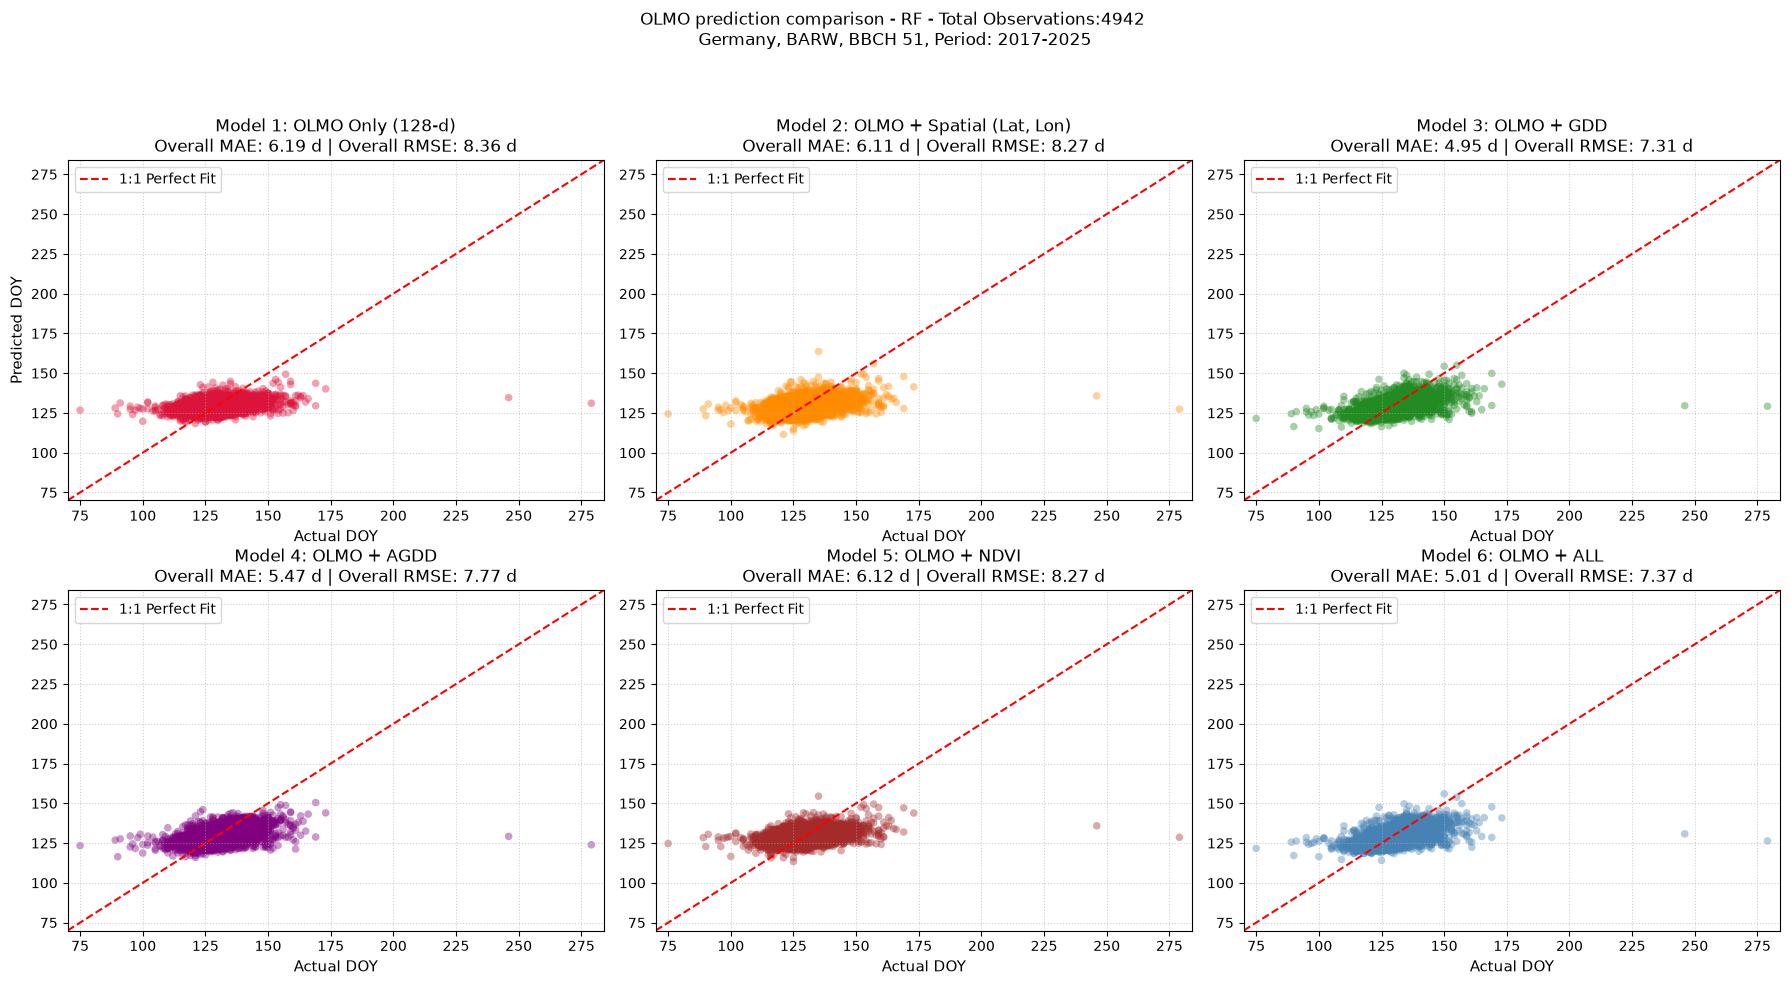

In [73]:
plt.figure(figsize=(18, 10))
model_configs = [
    (f"Model 1: {model} Only (128-d)", m1_preds, overall_m1_mae, overall_m1_rmse, "crimson"),
    (f"Model 2: {model} + Spatial (Lat, Lon)", m2_preds, overall_m2_mae, overall_m2_rmse, "darkorange"),
    (f"Model 3: {model} + GDD", m3_preds, overall_m3_mae, overall_m3_rmse, "forestgreen"),
    (f"Model 4: {model} + AGDD", m4_preds, overall_m4_mae, overall_m4_rmse, "purple"),
    (f"Model 5: {model} + NDVI", m5_preds, overall_m5_mae, overall_m5_rmse, "brown"),
    (f"Model 6: {model} + ALL", m6_preds, overall_m6_mae, overall_m6_rmse, "steelblue"),
]

min_val = min(actual_doy) - 5
max_val = max(actual_doy) + 5

for idx, (title, preds, mae_val, rmse_val, color) in enumerate(model_configs, start=1):
    plt.subplot(2, 3, idx)
    plt.scatter(actual_doy, preds, alpha=0.4, color=color, edgecolors="none", s=30)
    plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=1.5, label="1:1 Perfect Fit")
    
    plt.title(f"{title}\nOverall MAE: {mae_val:.2f} d | Overall RMSE: {rmse_val:.2f} d", fontsize=12)
    plt.xlabel("Actual DOY", fontsize=11)
    if idx == 1:
        plt.ylabel("Predicted DOY", fontsize=11)
        
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.suptitle(f"{model} prediction comparison - RF - Total Observations:{len(df_clean)} \n{final_name}")
plt.subplots_adjust(top=0.83)
plt.savefig(summary_save_path / f"scatter_comparison_{model.lower()}_rf.png", dpi=300)
plt.show()

### 2.5 $R^2$ Decomposition & Per-Year LOYOCV Trajectory Plots (Random Forest, Unreduced Features)

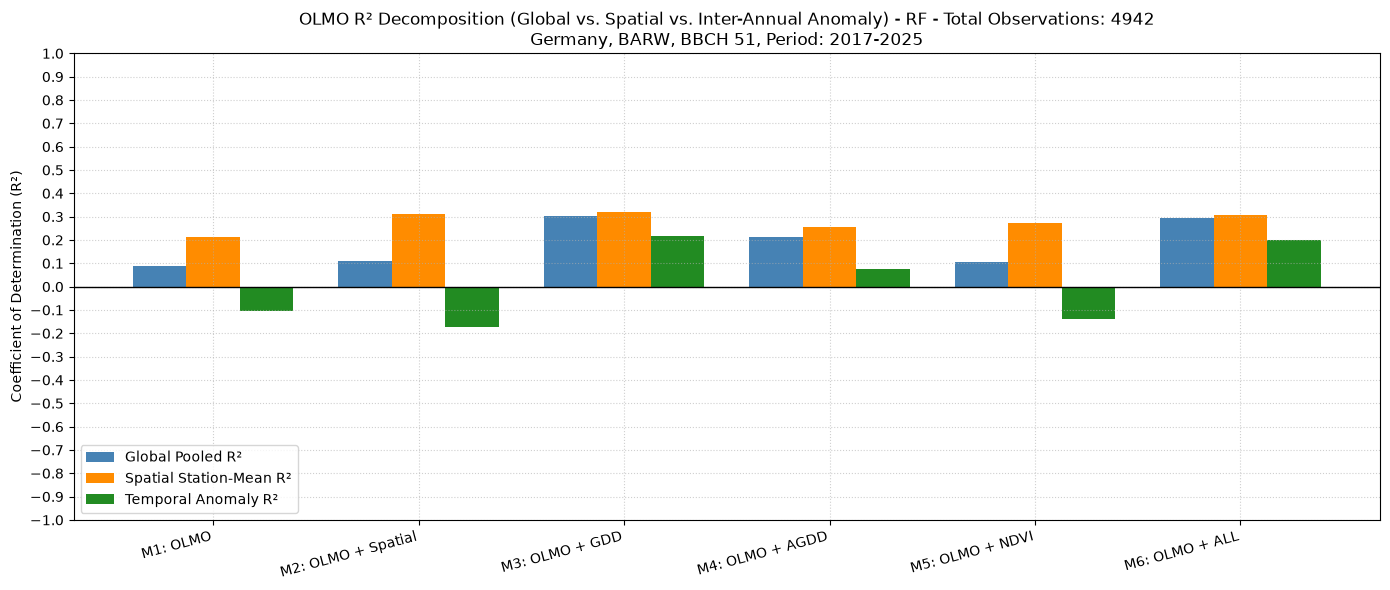

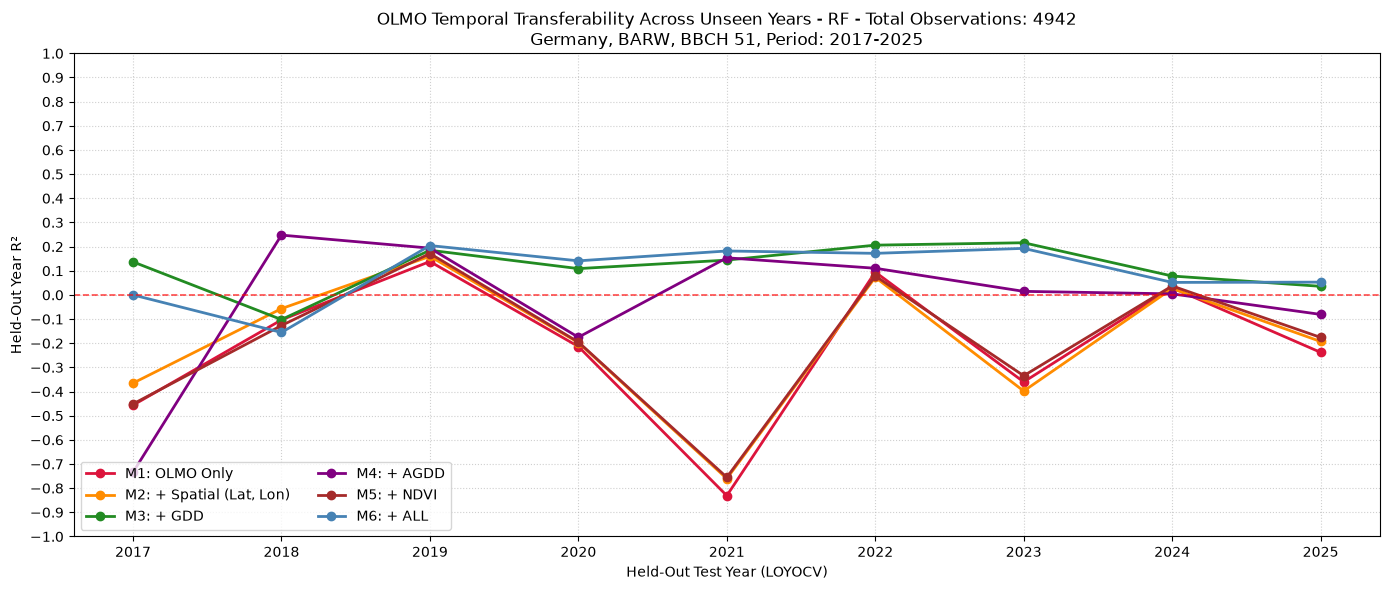

In [76]:
from sklearn.metrics import r2_score

# Ensure actual_doy is a NumPy array for boolean masking
actual_doy_arr = np.asarray(actual_doy)

# Build station identifier from df_clean to separate spatial vs. temporal variance
if "PEP_ID" in df_clean.columns:
    station_ids = df_clean["PEP_ID"].values
else:
    station_ids = (
        df_clean["Latitude"].round(4).astype(str)
        + "_"
        + df_clean["Longitude"].round(4).astype(str)
    ).values

years_arr = df_clean["Year"].astype(int).values

fm_unreduced_models = [
    (f"M1: {model} Only", np.asarray(m1_preds), "crimson"),
    ("M2: + Spatial (Lat, Lon)", np.asarray(m2_preds), "darkorange"),
    ("M3: + GDD", np.asarray(m3_preds), "forestgreen"),
    ("M4: + AGDD", np.asarray(m4_preds), "purple"),
    ("M5: + NDVI", np.asarray(m5_preds), "brown"),
    ("M6: + ALL", np.asarray(m6_preds), "steelblue"),
]

# R² Decomposition Plot: Global vs. Spatial vs. Temporal Anomaly R² (RF)
global_r2_list = []
spatial_r2_list = []
temporal_r2_list = []
short_labels = [
    f"M1: {model}",
    f"M2: {model} + Spatial",
    f"M3: {model} + GDD",
    f"M4: {model} + AGDD",
    f"M5: {model} + NDVI",
    f"M6: {model} + ALL",
]

for _, preds, _ in fm_unreduced_models:
    # 1. Global Pooled R²
    g_r2 = r2_score(actual_doy_arr, preds)

    # 2. Spatial Station-Mean R² & 3. Temporal Anomaly R² (ΔDOY)
    df_tmp = pd.DataFrame({
        "Station": station_ids,
        "Actual": actual_doy_arr,
        "Pred": preds,
    })
    st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
    s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

    df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
    obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
    pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
    t_r2 = r2_score(obs_anom, pred_anom)

    global_r2_list.append(g_r2)
    spatial_r2_list.append(s_r2)
    temporal_r2_list.append(t_r2)

# Save R² Decomposition values to CSV
df_r2_decomposition = pd.DataFrame({
    "Model_Key": [f"M{i}" for i in range(1, len(fm_unreduced_models) + 1)],
    "Model_Label": short_labels,
    "Global_Pooled_R2": np.round(global_r2_list, 4),
    "Spatial_Station_Mean_R2": np.round(spatial_r2_list, 4),
    "Temporal_Anomaly_R2": np.round(temporal_r2_list, 4),
})
display(df_r2_decomposition)
df_r2_decomposition.to_csv(
    summary_save_path / f"r2_decomposition_{model.lower()}_rf_unreduced.csv",
    sep=";",
    index=False,
)

x_pos = np.arange(len(fm_unreduced_models))
bar_width = 0.26
y_ticks = np.arange(-1,1.1,0.1)

plt.figure(figsize=(14, 6))
plt.bar(
    x_pos - bar_width,
    global_r2_list,
    width=bar_width,
    label="Global Pooled R²",
    color="steelblue",
)
plt.bar(
    x_pos,
    spatial_r2_list,
    width=bar_width,
    label="Spatial Station-Mean R²",
    color="darkorange",
)
plt.bar(
    x_pos + bar_width,
    temporal_r2_list,
    width=bar_width,
    label="Temporal Anomaly R²",
    color="forestgreen",
)

plt.axhline(0, color="black", lw=1.0)
plt.xticks(x_pos, short_labels, rotation=15, ha="right")
plt.yticks(y_ticks)
plt.ylabel("Coefficient of Determination (R²)")
plt.title(
    f"{model} R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) - "
    f"RF - Total Observations: {len(df_clean)}\n{final_name}"
)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", frameon=True)

plt.tight_layout()
plt.savefig(
    summary_save_path / f"r2_decomposition_{model.lower()}_rf_unreduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Per-Year LOYOCV R² Trajectory Across Held-Out Years (RF)
unique_years_plot = sorted(np.unique(years_arr))
df_r2_per_year = pd.DataFrame({"Test_Year": unique_years_plot})

plt.figure(figsize=(14, 6))

for idx, (m_label, preds, color) in enumerate(fm_unreduced_models, start=1):
    yearly_r2 = []
    for yr in unique_years_plot:
        mask = years_arr == yr
        yearly_r2.append(r2_score(actual_doy_arr[mask], preds[mask]))

    df_r2_per_year[f"M{idx}_R2"] = np.round(yearly_r2, 4)

    plt.plot(
        unique_years_plot,
        yearly_r2,
        marker="o",
        lw=2,
        color=color,
        label=m_label,
    )

# Save Per-Year R² values to CSV
display(df_r2_per_year)
df_r2_per_year.to_csv(
    summary_save_path / f"r2_per_year_{model.lower()}_rf_unreduced.csv",
    sep=";",
    index=False,
)

plt.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
plt.title(
    f"{model} Temporal Transferability Across Unseen Years - RF - "
    f"Total Observations: {len(df_clean)}\n{final_name}"
)
plt.xlabel("Held-Out Test Year (LOYOCV)")
plt.ylabel("Held-Out Year R²")
plt.xticks(unique_years_plot)
plt.yticks(y_ticks)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    summary_save_path / f"r2_per_year_{model.lower()}_rf_unreduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### 2.6 LOYOCV Hyperparameter Search (XGBoost, Unreduced Features)

In [39]:
# Hyperparameter search space for Random Forest
print("=" * 80)
print(f"RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1-6 FOR XGBOOST - {model}")
print("=" * 80)

for model_key, feat_cols in models_to_tune.items():
    print(f"\nTuning {model_key} (Total Features: {len(feat_cols)})...")

    X_subset = df_clean[feat_cols]

    # Adapt feature subsampling ratio to feature space size
    if len(feat_cols) <= 3:
        colsample_dist = [1.0]
    else:
        colsample_dist = uniform(0.30, 0.50)  # Randomly samples between 30% and 80%

    xgb_param_distributions = {
        # Ensemble size and shrinkage
        "n_estimators": randint(150, 350),
        "learning_rate": uniform(0.02, 0.08),  # Range: 0.02 to 0.10
        # Tree architecture (keep shallow for small N)
        "max_depth": randint(3, 6),            # Depths 3, 4, 5
        "min_child_weight": randint(2, 7),     # Analogous to min_samples_leaf (2 to 6)
        "gamma": uniform(0.0, 1.5),            # Minimum loss reduction for a split
        # Stochastic sampling
        "subsample": uniform(0.65, 0.30),      # Row subsampling (0.65 to 0.95)
        "colsample_bytree": colsample_dist,    # Column subsampling
        # Regularization
        "reg_alpha": [0.0, 0.1, 1.0],
        "reg_lambda": [1.0, 3.0, 8.0],
    }

    xgb_search = RandomizedSearchCV(
        estimator=XGBRegressor(
            objective="reg:squarederror",
            eval_metric="mae",
            random_state=42,
            n_jobs=1,  # Keep inner booster single-threaded
        ),
        param_distributions=xgb_param_distributions,
        n_iter=25,
        scoring="neg_mean_absolute_error",
        cv=logo,
        random_state=42,
        n_jobs=-1,  # Parallelize across CV folds/iterations
        verbose=0,
    )

    # Fit using groups to enforce Leave-One-Year-Out validation
    xgb_search.fit(X_subset, y_all, groups=groups_all)

    best_params_dict[model_key] = xgb_search.best_params_
    print(f" -> Best LOYOCV MAE: {-xgb_search.best_score_:.2f} days")
    print(f" -> Optimal Parameters: {xgb_search.best_params_}")

# Prediction lists for pooled evaluation
m1_preds = []
m2_preds = []
m3_preds = []
m4_preds = []
m5_preds = []
m6_preds = []
actual_doy = []
test_years_list = []
fold_results = []

print(
    f"Model 1 ({model} Only):        "
    f" {len(features_m1_embedding_only)} features"
)
print(
    f"Model 2 ({model} + Spatial):   "
    f" {len(features_m2_embedding_spatial)} features"
)
print(
    f"Model 3 ({model} + GDD ):      "
    f" {len(features_m3_embedding_GDD)} features"
)
print(
    f"Model 4 ({model} + AGDD):      "
    f" {len(features_m4_embedding_AGDD)} features"
)
print(
    f"Model 5 ({model} + NDVI):     "
    f" {len(features_m5_embedding_NDVI)} features"
)
print(
    f"Model 6 ({model} + ALL):      "
    f" {len(features_m6_embedding_all)} features"
)
print(f"Total LOYOCV folds:            {len(unique_years)} years")

RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1-6 FOR XGBOOST - OLMO

Tuning M1 (Total Features: 128)...
 -> Best LOYOCV MAE: 6.18 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.7541329429833268), 'gamma': np.float64(0.35934283600045863), 'learning_rate': np.float64(0.03159158976729785), 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 332, 'reg_alpha': 1.0, 'reg_lambda': 8.0, 'subsample': np.float64(0.7226479814832278)}

Tuning M2 (Total Features: 130)...
 -> Best LOYOCV MAE: 6.16 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.7934434683002587), 'gamma': np.float64(1.1583671539449862), 'learning_rate': np.float64(0.03589725452273379), 'max_depth': 5, 'min_child_weight': 4, 'n_estimators': 230, 'reg_alpha': 1.0, 'reg_lambda': 8.0, 'subsample': np.float64(0.8813811040057837)}

Tuning M3 (Total Features: 493)...
 -> Best LOYOCV MAE: 6.23 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.6566223936114974), 'gamma': np.float64(1.14117757

### 2.7 Run LOYOCV Evaluation (XGBoost, Unreduced Features)

In [40]:
print(f"Starting LOYOCV across {len(unique_years)} folds...\n")

for test_year in unique_years:
  train_mask = df_clean["Year"] != test_year
  test_mask = df_clean["Year"] == test_year

  y_train = df_clean.loc[train_mask, "DOY"]
  y_test = df_clean.loc[test_mask, "DOY"]

# --- Model 1: TESSERA only ---
  xgb_m1 = XGBRegressor(
      **best_params_dict["M1"], random_state=42, n_jobs=-1
    )
  xgb_m1.fit(
      df_clean.loc[train_mask, features_m1_embedding_only], y_train
  )
  pred_m1 = xgb_m1.predict(
    df_clean.loc[test_mask, features_m1_embedding_only]
    )

    # --- Model 2: TESSERA & Lat/Lon ---
  xgb_m2 = XGBRegressor(
     **best_params_dict["M2"], random_state=42, n_jobs=-1
    )
  xgb_m2.fit(
    df_clean.loc[train_mask, features_m2_embedding_spatial], y_train
    )
  pred_m2 = xgb_m2.predict(
    df_clean.loc[test_mask, features_m2_embedding_spatial]
    )

    # --- Model 3: TESSERA & GDD ---
  xgb_m3 = XGBRegressor(
    **best_params_dict["M3"], random_state=42, n_jobs=-1
    )
  xgb_m3.fit(
      df_clean.loc[train_mask, features_m3_embedding_GDD], y_train
    )
  pred_m3 = xgb_m3.predict(
      df_clean.loc[test_mask, features_m3_embedding_GDD]
    )

    # --- Model 4: TESSERA & AGDD ---
  xgb_m4 = XGBRegressor(
      **best_params_dict["M4"], random_state=42, n_jobs=-1
    )
  xgb_m4.fit(
      df_clean.loc[train_mask, features_m4_embedding_AGDD], y_train
    )
  pred_m4 = xgb_m4.predict(
      df_clean.loc[test_mask, features_m4_embedding_AGDD]
    )

    # --- Model 5: Combined Multimodal ---
  xgb_m5 = XGBRegressor(
        **best_params_dict["M5"], random_state=42, n_jobs=-1
    )
  xgb_m5.fit(
        df_clean.loc[train_mask, features_m5_embedding_NDVI], y_train
    )
  pred_m5 = xgb_m5.predict(
        df_clean.loc[test_mask, features_m5_embedding_NDVI]
    )

    # --- Model 6: Combined Multimodal ---
  xgb_m6 = XGBRegressor(
        **best_params_dict["M6"], random_state=42, n_jobs=-1  
    )
  xgb_m6.fit(
        df_clean.loc[train_mask, features_m6_embedding_all], y_train
        )
  pred_m6 = xgb_m6.predict(
        df_clean.loc[test_mask, features_m6_embedding_all]
    )
    
  # Fold metrics
  mae_m1 = mean_absolute_error(y_test, pred_m1)
  rmse_m1 = np.sqrt(mean_squared_error(y_test, pred_m1))

  mae_m2 = mean_absolute_error(y_test, pred_m2)
  rmse_m2 = np.sqrt(mean_squared_error(y_test, pred_m2))

  mae_m3 = mean_absolute_error(y_test, pred_m3)
  rmse_m3 = np.sqrt(mean_squared_error(y_test, pred_m3))

  mae_m4 = mean_absolute_error(y_test, pred_m4)
  rmse_m4 = np.sqrt(mean_squared_error(y_test, pred_m4))

  mae_m5 = mean_absolute_error(y_test, pred_m5)
  rmse_m5 = np.sqrt(mean_squared_error(y_test, pred_m5))

  mae_m6 = mean_absolute_error(y_test, pred_m6)
  rmse_m6 = np.sqrt(mean_squared_error(y_test, pred_m6))

  fold_results.append(
        {
            "Test_Year": test_year,
            "N_Samples": len(y_test),
            f"M1_{model}_128d_MAE": round(mae_m1, 2),
            f"M1_{model}_128d_RMSE": round(rmse_m1, 2),
            f"M2_{model}_LatLon_MAE": round(mae_m2, 2),
            f"M2_{model}_LatLon_RMSE": round(rmse_m2, 2),
            f"M3_{model}_GDD_MAE": round(mae_m3, 2),
            f"M3_{model}_GDD_RMSE": round(rmse_m3, 2),
            f"M4_{model}_AGDD_MAE": round(mae_m4, 2),
            f"M4_{model}_AGDD_RMSE": round(rmse_m4, 2),
            f"M5_{model}_NDVI_MAE": round(mae_m5, 2),
            f"M5_{model}_NDVI_RMSE": round(rmse_m5, 2),
            "M6_Combined_MAE": round(mae_m6, 2),
            "M6_Combined_RMSE": round(rmse_m6, 2),
        }
    )

  m1_preds.extend(pred_m1)
  m2_preds.extend(pred_m2)
  m3_preds.extend(pred_m3)
  m4_preds.extend(pred_m4)
  m5_preds.extend(pred_m5)
  m6_preds.extend(pred_m6)
  actual_doy.extend(y_test.values)
  test_years_list.extend([test_year] * len(y_test))

  print(
        f"Year {test_year} (N={len(y_test):3d}) "
        f"M1 ({model} 128-d) MAE: {mae_m1:5.2f} d "
        f"M2 ({model} + Lat/Lon) MAE: {mae_m2:5.2f} d "
        f"M3 ({model} + GDD) MAE: {mae_m3:5.2f} d "
        f"M4 ({model} + AGDD) MAE: {mae_m4:5.2f} d "
        f"M5 ({model} + NDVI) MAE: {mae_m5:5.2f} d "
        f"M6 (Combined) MAE: {mae_m6:5.2f} d "
    )

print("\nLOYOCV evaluation finished!")


Starting LOYOCV across 9 folds...

Year 2017 (N=621) M1 (OLMO 128-d) MAE:  5.81 d M2 (OLMO + Lat/Lon) MAE:  5.63 d M3 (OLMO + GDD) MAE:  4.89 d M4 (OLMO + AGDD) MAE:  4.84 d M5 (OLMO + NDVI) MAE:  5.86 d M6 (Combined) MAE:  4.45 d 
Year 2018 (N=598) M1 (OLMO 128-d) MAE:  5.31 d M2 (OLMO + Lat/Lon) MAE:  5.04 d M3 (OLMO + GDD) MAE:  4.14 d M4 (OLMO + AGDD) MAE:  4.27 d M5 (OLMO + NDVI) MAE:  5.14 d M6 (Combined) MAE:  4.02 d 
Year 2019 (N=592) M1 (OLMO 128-d) MAE:  5.80 d M2 (OLMO + Lat/Lon) MAE:  5.78 d M3 (OLMO + GDD) MAE:  7.40 d M4 (OLMO + AGDD) MAE:  5.37 d M5 (OLMO + NDVI) MAE:  5.71 d M6 (Combined) MAE:  6.24 d 
Year 2020 (N=579) M1 (OLMO 128-d) MAE:  6.24 d M2 (OLMO + Lat/Lon) MAE:  6.29 d M3 (OLMO + GDD) MAE:  8.15 d M4 (OLMO + AGDD) MAE:  7.83 d M5 (OLMO + NDVI) MAE:  6.12 d M6 (Combined) MAE:  6.46 d 
Year 2021 (N=543) M1 (OLMO 128-d) MAE:  8.12 d M2 (OLMO + Lat/Lon) MAE:  8.08 d M3 (OLMO + GDD) MAE:  5.03 d M4 (OLMO + AGDD) MAE:  4.98 d M5 (OLMO + NDVI) MAE:  7.79 d M6 (Comb

### 2.8 Summarize, Save & Scatter Plots (XGBoost, Unreduced Features)


OVERALL LOYOCV BENCHMARK RESULTS (2017 onwards) (germany_barw_bbch51_2017-01-01_2025-12-31)
Model 1: OLMO Embeddings --> Overall MAE:  6.19 days | Overall RMSE: 8.36 days
Model 2: OLMO + (Latitude, Longitude) --> Overall MAE:  6.11 days | Overall RMSE: 8.27 days
Model 3: OLMO + GDD --> Overall MAE:  4.95 days | Overall RMSE: 7.31 days
Model 4: OLMO + Accumulated GDD Profile (Latitude, Longitude + 365 AGDD Columns) --> Overall MAE:  5.47 days | Overall RMSE: 7.77 days
Model 5: OLMO + NDVI Profile (Latitude, Longitude + 365 Daily NDVI Columns) --> Overall MAE:  6.12 days | Overall RMSE: 8.27 days
Model 6: OLMO + ALL --> Overall MAE:  5.01 days | Overall RMSE: 7.37 days


,Test_Year,N_Samples,M1_OLMO_MAE,M1_OLMO_RMSE,M2_OLMO_LatLon_MAE,M2_OLMO_LatLon_RMSE,M3_OLMO_GDD_MAE,M3_OLMO_GDD_RMSE,M4_OLMO_AGDD_MAE,M4_OLMO_AGDD_RMSE,M5_OLMO_NDVI_MAE,M5_OLMO_NDVI_RMSE,M6_OLMO_Combined_MAE,M6_OLMO_Combined_RMSE
0,2017,621,5.81,7.31,5.54,7.08,4.05,5.63,6.51,7.98,5.79,7.30,4.51,6.06
1,2018,598,5.31,6.78,5.14,6.64,5.12,6.78,4.05,5.60,5.35,6.85,5.29,6.94
2,2019,592,5.80,7.77,5.76,7.68,5.54,7.56,5.65,7.52,5.68,7.62,5.52,7.47
3,2020,579,6.24,7.79,6.18,7.73,5.05,6.67,6.22,7.66,6.15,7.73,4.93,6.55
4,2021,543,8.12,9.86,7.96,9.67,4.82,6.74,4.78,6.71,7.92,9.66,4.66,6.59
5,2022,529,4.44,6.05,4.63,6.13,4.12,5.67,4.33,6.00,4.59,6.11,4.22,5.79
6,2023,511,5.65,7.39,5.78,7.49,3.86,5.61,4.55,6.29,5.62,7.32,3.93,5.69
7,2024,488,6.60,11.64,6.55,11.66,5.43,11.34,5.81,11.79,6.56,11.59,5.52,11.50
8,2025,481,8.08,9.91,7.84,9.73,6.74,8.75,7.45,9.26,7.78,9.66,6.61,8.67


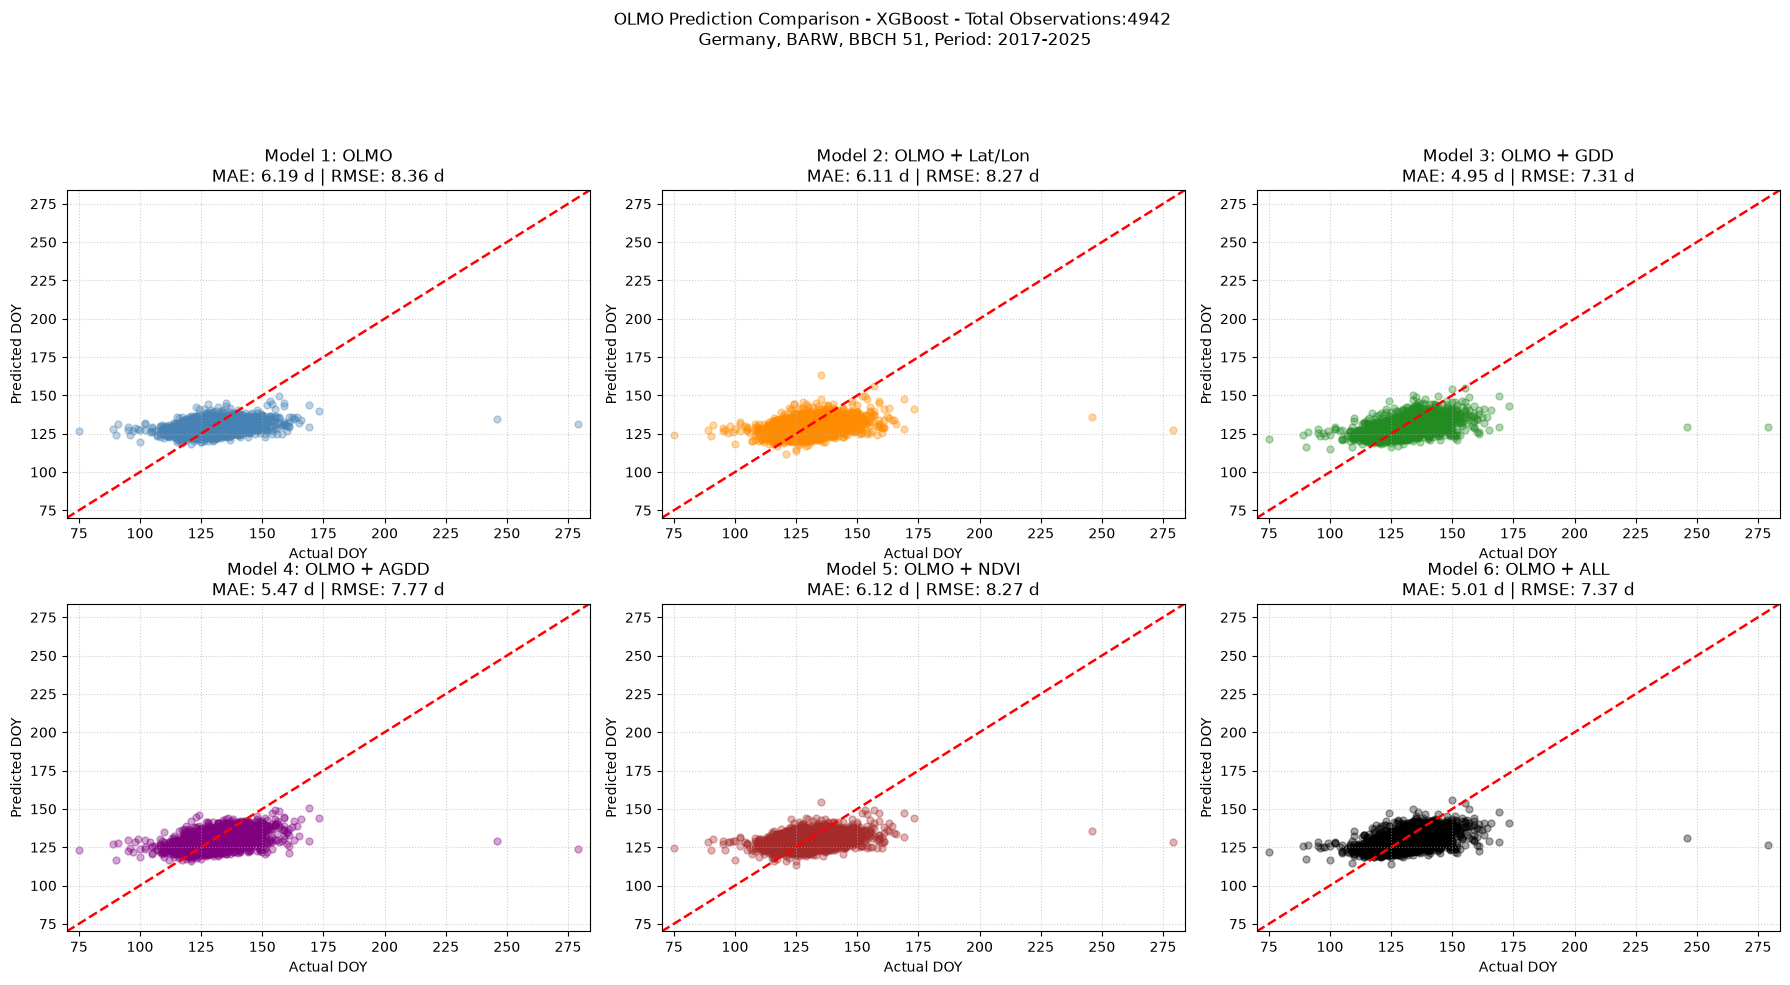

In [75]:
df_folds = pd.DataFrame(fold_results)

overall_m1_mae = mean_absolute_error(actual_doy, m1_preds)
overall_m1_rmse = np.sqrt(mean_squared_error(actual_doy, m1_preds))
overall_m2_mae = mean_absolute_error(actual_doy, m2_preds)
overall_m2_rmse = np.sqrt(mean_squared_error(actual_doy, m2_preds))
overall_m3_mae = mean_absolute_error(actual_doy, m3_preds)
overall_m3_rmse = np.sqrt(mean_squared_error(actual_doy, m3_preds))
overall_m4_mae = mean_absolute_error(actual_doy, m4_preds)
overall_m4_rmse = np.sqrt(mean_squared_error(actual_doy, m4_preds))
overall_m5_mae = mean_absolute_error(actual_doy, m5_preds)
overall_m5_rmse = np.sqrt(mean_squared_error(actual_doy, m5_preds))
overall_m6_mae = mean_absolute_error(actual_doy, m6_preds)
overall_m6_rmse = np.sqrt(mean_squared_error(actual_doy, m6_preds))

# Print overall results
print(f"\n{'='*80}")
print(f"OVERALL LOYOCV BENCHMARK RESULTS (2017 onwards) ({selected_folder.name})")
print(f"{'='*80}")
print(f"Model 1: {model} Embeddings --> Overall MAE:  {overall_m1_mae:.2f} days | Overall RMSE: {overall_m1_rmse:.2f} days")
print(f"Model 2: {model} + (Latitude, Longitude) --> Overall MAE:  {overall_m2_mae:.2f} days | Overall RMSE: {overall_m2_rmse:.2f} days")
print(f"Model 3: {model} + GDD --> Overall MAE:  {overall_m3_mae:.2f} days | Overall RMSE: {overall_m3_rmse:.2f} days")
print(f"Model 4: {model} + Accumulated GDD Profile (Latitude, Longitude + 365 AGDD Columns) --> Overall MAE:  {overall_m4_mae:.2f} days | Overall RMSE: {overall_m4_rmse:.2f} days")
print(f"Model 5: {model} + NDVI Profile (Latitude, Longitude + 365 Daily NDVI Columns) --> Overall MAE:  {overall_m5_mae:.2f} days | Overall RMSE: {overall_m5_rmse:.2f} days")
print(f"Model 6: {model} + ALL --> Overall MAE:  {overall_m6_mae:.2f} days | Overall RMSE: {overall_m6_rmse:.2f} days")

display(df_folds)

results_path_filtered = summary_save_path / f"{model.lower()}_loyocv_results_xgboost.csv"
df_folds.to_csv(results_path_filtered, sep=";", index=False)

# Scatter plots for the models
plt.figure(figsize=(18, 10))

models_plot = [
    (f"Model 1: {model}", m1_preds, overall_m1_mae, overall_m1_rmse, "steelblue"),
    (f"Model 2: {model} + Lat/Lon", m2_preds, overall_m2_mae, overall_m2_rmse, "darkorange"),
    (f"Model 3: {model} + GDD", m3_preds, overall_m3_mae, overall_m3_rmse, "forestgreen"),
    (f"Model 4: {model} + AGDD", m4_preds, overall_m4_mae, overall_m4_rmse, "purple"),
    (f"Model 5: {model} + NDVI", m5_preds, overall_m5_mae, overall_m5_rmse, "brown"),
    (f"Model 6: {model} + ALL", m6_preds, overall_m6_mae, overall_m6_rmse, "black")]

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot, 1):
    plt.subplot(2, 3, i)
    plt.scatter(actual_doy, predictions, alpha=0.35, color=color, s=25)
    plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=1.8, label="1:1 Fit")
    plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d")
    plt.xlabel("Actual DOY")
    plt.ylabel("Predicted DOY")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)

plt.tight_layout()
plt.subplots_adjust(top=0.8)
plt.suptitle(f"{model} Prediction Comparison - XGBoost - Total Observations:{len(df_clean)} \n{final_name}")
# Save plot
plt.savefig(summary_save_path / f"{model.lower()}_scatter_comparison_xgboost", dpi=300, bbox_inches="tight")
plt.show()

### 2.9 $R^2$ Decomposition & Per-Year LOYOCV Trajectory Plots (XGBoost, Unreduced Features)

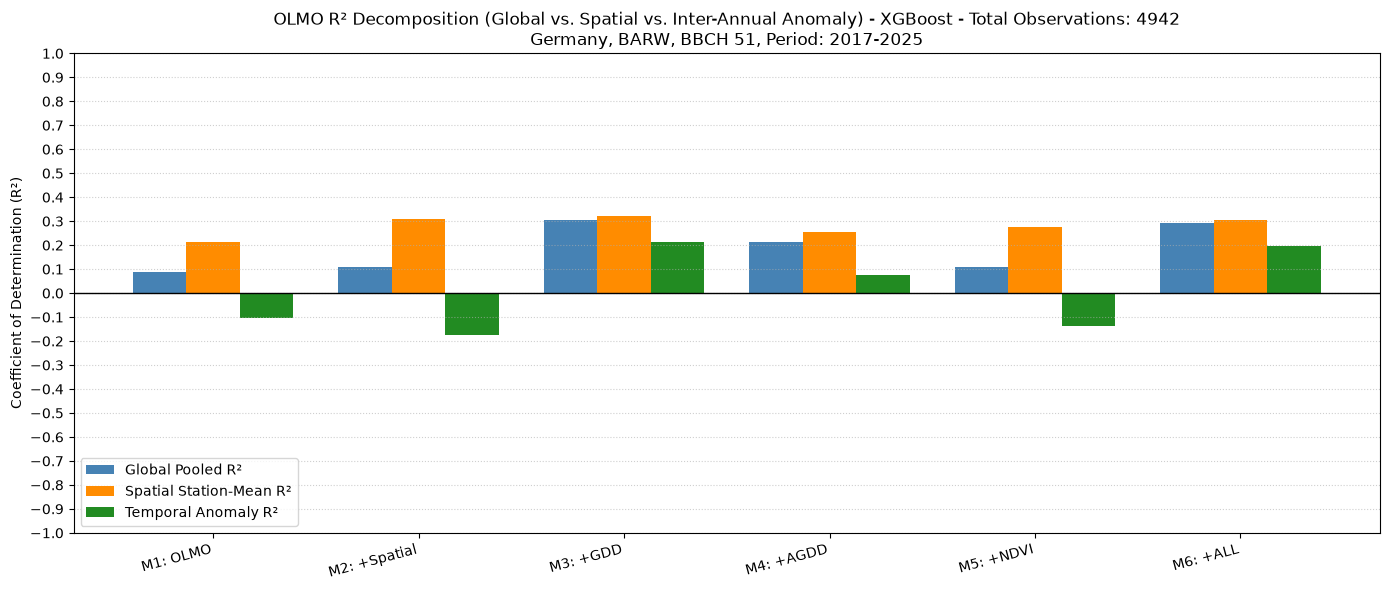

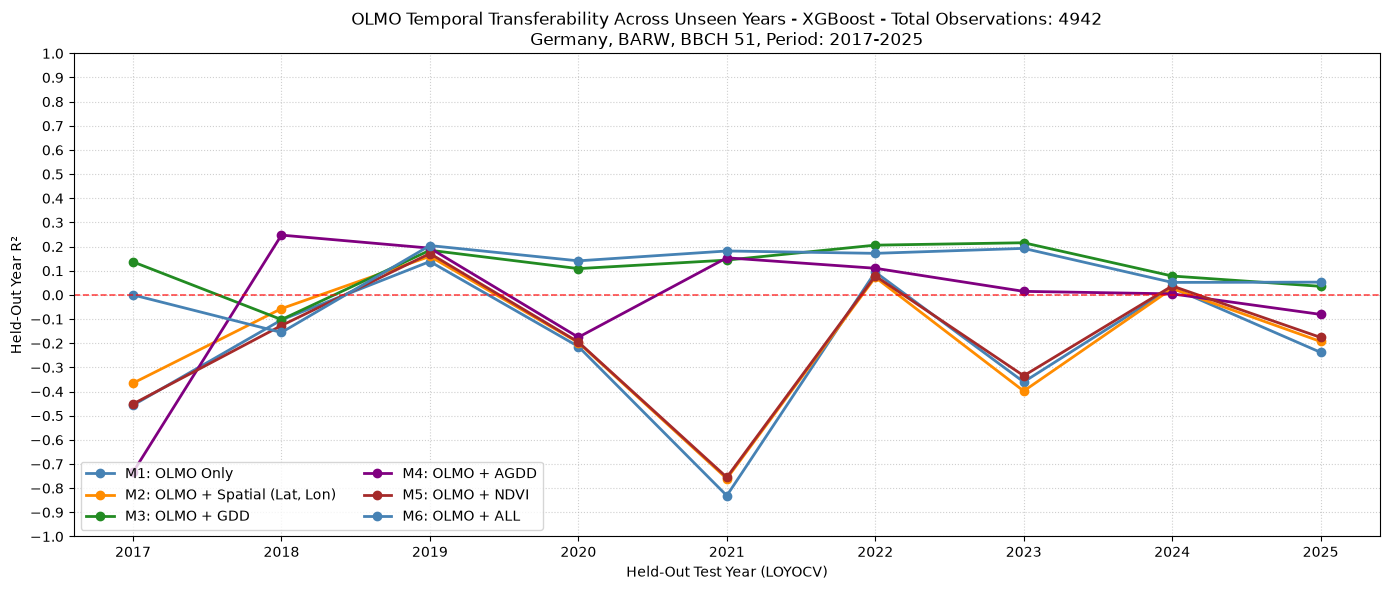

In [78]:
from sklearn.metrics import r2_score

# Ensure actual_doy is a NumPy array for boolean masking
actual_doy_arr = np.asarray(actual_doy)

# Build station identifier from df_clean to separate spatial vs. temporal variance
if "PEP_ID" in df_clean.columns:
    station_ids = df_clean["PEP_ID"].values
else:
    station_ids = (
        df_clean["Latitude"].round(4).astype(str)
        + "_"
        + df_clean["Longitude"].round(4).astype(str)
    ).values

years_arr = df_clean["Year"].astype(int).values

fm_unreduced_models = [
    (f"M1: {model} Only", np.asarray(m1_preds), "steelblue"),
    (f"M2: {model} + Spatial (Lat, Lon)", np.asarray(m2_preds), "darkorange"),
    (f"M3: {model} + GDD", np.asarray(m3_preds), "forestgreen"),
    (f"M4: {model} + AGDD", np.asarray(m4_preds), "purple"),
    (f"M5: {model} + NDVI", np.asarray(m5_preds), "brown"),
    (f"M6: {model} + ALL", np.asarray(m6_preds), "steelblue"),
]

# R² Decomposition Plot: Global vs. Spatial vs. Temporal Anomaly R² (XGBoost)
global_r2_list = []
spatial_r2_list = []
temporal_r2_list = []
short_labels = [
    f"M1: {model}",
    "M2: +Spatial",
    "M3: +GDD",
    "M4: +AGDD",
    "M5: +NDVI",
    "M6: +ALL",
]

for _, preds, _ in fm_unreduced_models:
    # 1. Global Pooled R²
    g_r2 = r2_score(actual_doy_arr, preds)

    # 2. Spatial Station-Mean R² & 3. Temporal Anomaly R² (ΔDOY)
    df_tmp = pd.DataFrame({
        "Station": station_ids,
        "Actual": actual_doy_arr,
        "Pred": preds,
    })
    st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
    s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

    df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
    obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
    pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
    t_r2 = r2_score(obs_anom, pred_anom)

    global_r2_list.append(g_r2)
    spatial_r2_list.append(s_r2)
    temporal_r2_list.append(t_r2)

# Save R² Decomposition values to CSV
df_r2_decomposition = pd.DataFrame({
    "Model_Key": [f"M{i}" for i in range(1, len(fm_unreduced_models) + 1)],
    "Model_Label": short_labels,
    "Global_Pooled_R2": np.round(global_r2_list, 4),
    "Spatial_Station_Mean_R2": np.round(spatial_r2_list, 4),
    "Temporal_Anomaly_R2": np.round(temporal_r2_list, 4),
})
display(df_r2_decomposition)
df_r2_decomposition.to_csv(
    summary_save_path / f"r2_decomposition_{model.lower()}_xgboost_unreduced.csv",
    sep=";",
    index=False,
)

x_pos = np.arange(len(fm_unreduced_models))
bar_width = 0.26

plt.figure(figsize=(14, 6))
plt.bar(
    x_pos - bar_width,
    global_r2_list,
    width=bar_width,
    label="Global Pooled R²",
    color="steelblue",
)
plt.bar(
    x_pos,
    spatial_r2_list,
    width=bar_width,
    label="Spatial Station-Mean R²",
    color="darkorange",
)
plt.bar(
    x_pos + bar_width,
    temporal_r2_list,
    width=bar_width,
    label="Temporal Anomaly R²",
    color="forestgreen",
)

plt.axhline(0, color="black", lw=1.0)
plt.xticks(x_pos, short_labels, rotation=15, ha="right")
plt.yticks(y_ticks)
plt.ylabel("Coefficient of Determination (R²)")
plt.title(
    f"{model} R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) - "
    f"XGBoost - Total Observations: {len(df_clean)}\n{final_name}"
)
plt.grid(True, axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="lower left", frameon=True)

plt.tight_layout()
plt.savefig(
    summary_save_path / f"r2_decomposition_{model.lower()}_xgboost_unreduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Per-Year LOYOCV R² Trajectory Across Held-Out Years (XGBoost)
unique_years_plot = sorted(np.unique(years_arr))
df_r2_per_year = pd.DataFrame({"Test_Year": unique_years_plot})

plt.figure(figsize=(14, 6))

for idx, (m_label, preds, color) in enumerate(fm_unreduced_models, start=1):
    yearly_r2 = []
    for yr in unique_years_plot:
        mask = years_arr == yr
        yearly_r2.append(r2_score(actual_doy_arr[mask], preds[mask]))

    df_r2_per_year[f"M{idx}_R2"] = np.round(yearly_r2, 4)

    plt.plot(
        unique_years_plot,
        yearly_r2,
        marker="o",
        lw=2,
        color=color,
        label=m_label,
    )

# Save Per-Year R² values to CSV
display(df_r2_per_year)
df_r2_per_year.to_csv(
    summary_save_path / f"r2_per_year_{model.lower()}_xgboost_unreduced.csv",
    sep=";",
    index=False,
)

plt.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
plt.title(
    f"{model} Temporal Transferability Across Unseen Years - XGBoost - "
    f"Total Observations: {len(df_clean)}\n{final_name}"
)
plt.xlabel("Held-Out Test Year (LOYOCV)")
plt.ylabel("Held-Out Year R²")
plt.xticks(unique_years_plot)
plt.yticks(y_ticks)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    summary_save_path / f"r2_per_year_{model.lower()}_xgboost_unreduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## Part 3: Domain-Reduced Baseline Features + FM Embeddings (Models M1–M6)
### 3.1 Initialize Reduced DataFrame

In [43]:
# dataframe to use 
df_reduced = pd.DataFrame()

# Get the basic columns of the df_final
df_reduced["Year"] = df_clean["Year"].astype(int)
df_reduced["Latitude"] = df_clean["Latitude"]
df_reduced["Longitude"] = df_clean["Longitude"]
df_reduced["DOY"] = df_clean["DOY"]

# Get TESSERA embeddings
for col in embedding_cols:
    df_reduced[col] = df_clean[col]


C:\Users\jimpa\AppData\Local\Temp\ipykernel_21236\1656698574.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_reduced[col] = df_clean[col]
C:\Users\jimpa\AppData\Local\Temp\ipykernel_21236\1656698574.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_reduced[col] = df_clean[col]
C:\Users\jimpa\AppData\Local\Temp\ipykernel_21236\1656698574.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all column

### 3.2 Feature Reduction for Daily GDD (12 Monthly Sums + Chilling & Heat Stress)

In [44]:
# We compress 365 noisy daily columns into 12 monthly thermal integrals that
# represent discrete developmental phases (winter dormancy, spring resumption,
# summer maturation, and autumn harvest), plus chilling and heat-stress indicators.
gdd_cols = [c for c in df_clean.columns if c.startswith("GDD_doy_")]
if gdd_cols:
    gdd_mat = df_clean[gdd_cols].values  # Shape: (N, 365)

    # 1.1 Monthly Thermal Integrals (January to December)
    # Each slice sums the thermal energy accrued specifically within that 30/31-day calendar block.
    # Jan (1-31), Feb (32-59), Mar (60-90), Apr (91-120), May (121-151), Jun (152-181),
    # Jul (182-212), Aug (213-243), Sep (244-273), Oct (274-304), Nov (305-334), Dec (335-365).
    month_slices = {
        "Jan": (0, 31),
        "Feb": (31, 59),
        "Mar": (59, 90),
        "Apr": (90, 120),
        "May": (120, 151),
        "Jun": (151, 181),
        "Jul": (181, 212),
        "Aug": (212, 243),
        "Sep": (243, 273),
        "Oct": (273, 304),
        "Nov": (304, 334),
        "Dec": (334, 365),
    }

    for month_name, (start_idx, end_idx) in month_slices.items():
        # Captures monthly heat velocity without forcing the tree to learn cross-column additions
        df_reduced[f"GDD_sum_{month_name}"] = gdd_mat[:, start_idx:end_idx].sum(axis=1)

    # 1.2 Dormancy Pause / Cold Delay Days (DOY 1 to 120: Jan 1 - Apr 30)
    # Counts days where GDD <= 0.5°C (mean temp <= base temp), directly capturing
    # winter chilling severity and early-season developmental stalls.
    df_reduced["GDD_cold_days_winter_spring"] = (gdd_mat[:, 0:120] <= 0.5).sum(axis=1)

    # 1.3 Summer Heat Concentration (DOY 152 to 243: Jun 1 - Aug 31)
    # Measures the magnitude of peak summer thermal forcing during grain/tuber filling.
    df_reduced["GDD_sum_summer_peak"] = gdd_mat[:, 151:243].sum(axis=1)

C:\Users\jimpa\AppData\Local\Temp\ipykernel_21236\3528406708.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_reduced[f"GDD_sum_{month_name}"] = gdd_mat[:, start_idx:end_idx].sum(axis=1)
C:\Users\jimpa\AppData\Local\Temp\ipykernel_21236\3528406708.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_reduced[f"GDD_sum_{month_name}"] = gdd_mat[:, start_idx:end_idx].sum(axis=1)
C:\Users\jimpa\AppData\Local\Temp\ipykernel_21236\3528406708.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the resul

### 3.3 Feature Reduction for Accumulated GDD (26 Bi-Weekly Checkpoints)

In [45]:
# Sampling at a fixed 14-day
agdd_checkpoints_doy = [
    14, 28, 42, 56, 70, 84, 98, 112, 126, 140, 154, 168, 182,
    196, 210, 224, 238, 252, 266, 280, 294, 308, 322, 336, 350, 365
]

for doy_val in agdd_checkpoints_doy:
    col_name = f"AGDD_doy_{doy_val}"
    if col_name in df_clean.columns:
        # Pre-computed cumulative heat sum allows trees to evaluate milestone completion at a single split
        df_reduced[f"AGDD_biweekly_doy_{doy_val}"] = df_clean[col_name]

# Spring accumulation acceleration (DOY 60 to DOY 154: early March to early June)
# Captures the slope of spring warming (fast warm spring vs. prolonged cold spring)
if "AGDD_doy_154" in df_clean.columns and "AGDD_doy_60" in df_clean.columns:
    df_reduced["AGDD_spring_velocity"] = df_clean["AGDD_doy_154"] - df_clean["AGDD_doy_60"]

C:\Users\jimpa\AppData\Local\Temp\ipykernel_21236\2886798994.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_reduced[f"AGDD_biweekly_doy_{doy_val}"] = df_clean[col_name]
C:\Users\jimpa\AppData\Local\Temp\ipykernel_21236\2886798994.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_reduced[f"AGDD_biweekly_doy_{doy_val}"] = df_clean[col_name]
C:\Users\jimpa\AppData\Local\Temp\ipykernel_21236\2886798994.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many

### 3.4 Feature Reduction for Daily NDVI (6 LSP Curve Metrics + 26 Bi-Weekly ANDVI Checkpoints)

In [46]:
# We extract: (a) 5 core Land Surface Phenology (LSP) curve parameters, and
# (b) 26 bi-weekly Accumulated NDVI (ANDVI) checkpoints representing cumulative biomass.
ndvi_cols = [c for c in df_clean.columns if c.startswith("NDVI_doy_")]
if ndvi_cols:
    ndvi_mat = df_clean[ndvi_cols].values  # Shape: (N, 365)

    # 3.1 Winter/Soil Baseline Reflectance (DOY 1 to 75)
    # Captures un-vegetated background soil and residue reflectance
    df_reduced["NDVI_base"] = np.min(ndvi_mat[:, 0:75], axis=1)

    # 3.2 Peak Canopy Value and Timing (DOY 60 to 300)
    # The day of maximum NDVI is the primary optical anchor for heading, flowering, and peak biomass
    ndvi_growth_window = ndvi_mat[:, 59:300]
    df_reduced["NDVI_max"] = np.max(ndvi_growth_window, axis=1)
    df_reduced["NDVI_peak_doy"] = np.argmax(ndvi_growth_window, axis=1) + 60

    # 3.3 Seasonal Canopy Amplitude
    # Difference between maximum green canopy and bare ground (total seasonal leaf capacity)
    df_reduced["NDVI_amplitude"] = df_reduced["NDVI_max"] - df_reduced["NDVI_base"]

    # 3.4 Maximum Green-up Velocity (Slope)
    # The maximum 7-day rate of change during the spring green-up surge
    ndvi_7d_diff = ndvi_growth_window[:, 7:] - ndvi_growth_window[:, :-7]
    df_reduced["NDVI_max_greenup_slope"] = np.max(ndvi_7d_diff, axis=1) / 7.0

    # 3.5 Total Integrated Seasonal Vigor (AUC)
    # Integral of NDVI exceeding background soil reflectance (proxy for total absorbed radiation)
    df_reduced["NDVI_AUC_seasonal"] = np.sum(np.clip(ndvi_mat - 0.20, 0, None), axis=1)

    # 3.6 Accumulated NDVI (ANDVI) Across the Full Year (26 Bi-Weekly Checkpoints)
    # We integrate daily active canopy cover (excess over soil threshold 0.15)
    # and sample cumulative intercepted radiation at the exact same 14-day intervals as AGDD.
    andvi_daily_integral = np.cumsum(np.clip(ndvi_mat - 0.15, 0, None), axis=1)
    for doy_val in agdd_checkpoints_doy:
        # ANDVI acts as the cumulative biomass odometer for the tree models
        df_reduced[f"ANDVI_biweekly_doy_{doy_val}"] = andvi_daily_integral[:, doy_val - 1]

C:\Users\jimpa\AppData\Local\Temp\ipykernel_21236\55353598.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_reduced["NDVI_base"] = np.min(ndvi_mat[:, 0:75], axis=1)
C:\Users\jimpa\AppData\Local\Temp\ipykernel_21236\55353598.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_reduced["NDVI_max"] = np.max(ndvi_growth_window, axis=1)
C:\Users\jimpa\AppData\Local\Temp\ipykernel_21236\55353598.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which h

### 3.5 Define Reduced Feature Sets & Run LOYOCV Hyperparameter Search (Random Forest)

In [47]:
# Create the different featur sets for the baselines 
features_m1_embedding_only = embedding_cols

features_m2_embedding_spatial = embedding_cols + ["Latitude", "Longitude"]

features_m3_embedding_GDD = embedding_cols + [
    c for c in df_reduced.columns if c.startswith("GDD_")
]

features_m4_embedding_AGDD = embedding_cols + [
    c for c in df_reduced.columns if c.startswith("AGDD_")
]

features_m5_embedding_NDVI = embedding_cols + [
    c for c in df_reduced.columns if c.startswith("NDVI_") or c.startswith("ANDVI_")
]

features_m6_embedding_all = embedding_cols + (
    ["Latitude", "Longitude"]
    + [c for c in df_reduced.columns if c.startswith("GDD_")]
    + [c for c in df_reduced.columns if c.startswith("AGDD_")]
    + [c for c in df_reduced.columns if c.startswith("NDVI_") or c.startswith("ANDVI_")]
)

# Set up dictionary for the baseline feature sets
models_to_tune = {
    "M1": features_m1_embedding_only,
    "M2": features_m2_embedding_spatial,
    "M3": features_m3_embedding_GDD,
    "M4": features_m4_embedding_AGDD,
    "M5": features_m5_embedding_NDVI,
    "M6": features_m6_embedding_all,
}

y_all = df_reduced["DOY"]
groups_all = df_reduced["Year"]
logo = LeaveOneGroupOut()

best_params_dict = {}

# 2. HYPERPARAMETER SEARCH ACROSS EACH BASELINE
print("=" * 80)
print(f"RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1 TO 6 (RANDOM FOREST - {model})")
print("=" * 80)

for model_key, feat_cols in models_to_tune.items():
    print(f"\nTuning {model_key} (Total Features: {len(feat_cols)})...")

    X_subset = df_reduced[feat_cols]

    # Adjust max_features distribution based on feature count
    if len(feat_cols) <= 3:
        max_feat_dist = [1.0]
    else:
        max_feat_dist = uniform(0.25, 0.50)  # samples between 25% and 75% of features

    param_distributions = {
        "n_estimators": randint(150, 350),
        "max_depth": [None, 12, 18, 25],
        "min_samples_leaf": randint(1, 5),
        "min_samples_split": randint(2, 6),
        "max_features": max_feat_dist,
    }

    rf_search = RandomizedSearchCV(
        estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
        param_distributions=param_distributions,
        n_iter=25,
        scoring="neg_mean_absolute_error",
        cv=logo,
        random_state=42,
        n_jobs=-1,
        verbose=0,
    )

    rf_search.fit(X_subset, y_all, groups=groups_all)

    best_params_dict[model_key] = rf_search.best_params_
    print(f" -> Best LOYOCV MAE: {-rf_search.best_score_:.2f} days")
    print(f" -> Optimal Parameters: {rf_search.best_params_}")

print("=" * 75)
print("FEATURE REDUCTION SUMMARY")
print("=" * 75)
print(f"Total Observation Records:               {len(df_reduced)}")
print(f"Model 1 ({model} Only):                  {len(features_m1_embedding_only):3d} features")
print(f"Model 2 ({model} + Spatial):             {len(features_m2_embedding_spatial):3d} features")
print(f"Model 3 ({model} + GDD):                 {len(features_m3_embedding_GDD):3d} features")
print(f"Model 4 ({model} + AGDD):                {len(features_m4_embedding_AGDD):3d} features")
print(f"Model 5 ({model} + NDVI):                {len(features_m5_embedding_NDVI):3d} features")
print(f"Model 6 ({model} + All Features):        {len(features_m6_embedding_all):3d} features")
print("=" * 75)

RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1 TO 6 (RANDOM FOREST - OLMO)

Tuning M1 (Total Features: 128)...
 -> Best LOYOCV MAE: 6.20 days
 -> Optimal Parameters: {'max_depth': 25, 'max_features': np.float64(0.3663856702151521), 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 339}

Tuning M2 (Total Features: 130)...
 -> Best LOYOCV MAE: 6.19 days
 -> Optimal Parameters: {'max_depth': 25, 'max_features': np.float64(0.4132703844029177), 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 339}

Tuning M3 (Total Features: 142)...
 -> Best LOYOCV MAE: 5.07 days
 -> Optimal Parameters: {'max_depth': 25, 'max_features': np.float64(0.4132703844029177), 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 339}

Tuning M4 (Total Features: 155)...
 -> Best LOYOCV MAE: 5.49 days
 -> Optimal Parameters: {'max_depth': 18, 'max_features': np.float64(0.6830880728874675), 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 301}

Tuning M5 (Total Feat

### 3.6 Run LOYOCV Evaluation (Random Forest, Reduced Features)

In [ ]:
# 5. EXECUTE LEAVE-ONE-YEAR-OUT CROSS-VALIDATION (LOYOCV) ON REDUCED FEATURES
unique_years = sorted(df_reduced["Year"].unique())

m1_preds, m2_preds, m3_preds, m4_preds, m5_preds, m6_preds = [], [], [], [], [], []
actual_doy = []
test_years_list = []
fold_results = []

print(f"Starting LOYOCV across {len(unique_years)} folds...\n")

for test_year in unique_years:
  train_mask = df_reduced["Year"] != test_year
  test_mask = df_reduced["Year"] == test_year

  y_train = df_reduced.loc[train_mask, "DOY"]
  y_test = df_reduced.loc[test_mask, "DOY"]

  # Fit Model 1: TESSERA Only
  rf_m1 = RandomForestRegressor(
    **best_params_dict["M1"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m1.fit(df_reduced.loc[train_mask, features_m1_embedding_only], y_train)
  pred_m1 = rf_m1.predict(df_reduced.loc[test_mask, features_m1_embedding_only])

  # Fit Model 2: TESSERA + Spatial
  rf_m2 = RandomForestRegressor(
    **best_params_dict["M2"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m2.fit(df_reduced.loc[train_mask, features_m2_embedding_spatial], y_train)
  pred_m2 = rf_m2.predict(df_reduced.loc[test_mask, features_m2_embedding_spatial])

  # Fit Model 3: TESSERA + GDD 
  rf_m3 = RandomForestRegressor(
    **best_params_dict["M3"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m3.fit(df_reduced.loc[train_mask, features_m3_embedding_GDD], y_train)
  pred_m3 = rf_m3.predict(df_reduced.loc[test_mask, features_m3_embedding_GDD])

  # Fit Model 4: TESSERA + AGDD 
  rf_m4 = RandomForestRegressor(
    **best_params_dict["M4"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m4.fit(df_reduced.loc[train_mask, features_m4_embedding_AGDD], y_train)
  pred_m4 = rf_m4.predict(df_reduced.loc[test_mask, features_m4_embedding_AGDD])

  # Fit Model 5: TESSERA + NDVI 
  rf_m5 = RandomForestRegressor(
    **best_params_dict["M5"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m5.fit(df_reduced.loc[train_mask, features_m5_embedding_NDVI], y_train)
  pred_m5 = rf_m5.predict(df_reduced.loc[test_mask, features_m5_embedding_NDVI])

  # Fit Model 6: TESSERA + ALL
  rf_m6 = RandomForestRegressor(
    **best_params_dict["M6"],
    random_state=42,
    n_jobs=-1,
  )
  rf_m6.fit(df_reduced.loc[train_mask, features_m6_embedding_all], y_train)
  pred_m6 = rf_m6.predict(df_reduced.loc[test_mask, features_m6_embedding_all])

  # Compute fold-level metrics
  mae_m1 = mean_absolute_error(y_test, pred_m1)
  rmse_m1 = np.sqrt(mean_squared_error(y_test, pred_m1))

  mae_m2 = mean_absolute_error(y_test, pred_m2)
  rmse_m2 = np.sqrt(mean_squared_error(y_test, pred_m2))

  mae_m3 = mean_absolute_error(y_test, pred_m3)
  rmse_m3 = np.sqrt(mean_squared_error(y_test, pred_m3))

  mae_m4 = mean_absolute_error(y_test, pred_m4)
  rmse_m4 = np.sqrt(mean_squared_error(y_test, pred_m4))

  mae_m5 = mean_absolute_error(y_test, pred_m5)
  rmse_m5 = np.sqrt(mean_squared_error(y_test, pred_m5))

  mae_m6 = mean_absolute_error(y_test, pred_m6)
  rmse_m6 = np.sqrt(mean_squared_error(y_test, pred_m6))

  fold_results.append({
      "Test_Year": test_year,
      "N_Samples": len(y_test),
      f"M1_{model}_Only_MAE": round(mae_m1, 2),
      f"M1_{model}_Only_RMSE": round(rmse_m1, 2),
      f"M2_{model}_Spatial_MAE": round(mae_m2, 2),
      f"M2_{model}_Spatial_RMSE": round(rmse_m2, 2),
      f"M3_{model}_GDD_MAE": round(mae_m3, 2),
      f"M3_{model}_GDD_RMSE": round(rmse_m3, 2),
      f"M4_{model}_AGDD_MAE": round(mae_m4, 2),
      f"M4_{model}_AGDD_RMSE": round(rmse_m4, 2),
      f"M5_{model}_NDVI_MAE": round(mae_m5, 2),
      f"M5_{model}_NDVI_RMSE": round(rmse_m5, 2),
      f"M6_{model}_All_MAE": round(mae_m6, 2),
      f"M6_{model}_All_RMSE": round(rmse_m6, 2),

  })

  m1_preds.extend(pred_m1)
  m2_preds.extend(pred_m2)
  m3_preds.extend(pred_m3)
  m4_preds.extend(pred_m4)
  m5_preds.extend(pred_m5)
  m6_preds.extend(pred_m6)
  actual_doy.extend(y_test.values)
  test_years_list.extend([test_year] * len(y_test))

  print(
      f"Year {test_year} (N={len(y_test):3d}) | "
      f"{model} Only MAE: {mae_m1:5.2f}d | "
      f"{model}+Spatial MAE: {mae_m2:5.2f}d | "
      f"Fusion ({model}+Reduced 12M GDD + Stress) MAE: {mae_m3:5.2f}d"
      f"Fusion ({model}+Reduced 26-Step AGDD) MAE: {mae_m4:5.2f}d"
      f"Fusion ({model}+Reduced NDVI LSP + ANDVI) MAE: {mae_m5:5.2f}d"
      f"Fusion ({model}+Reduced Combined Multimodal) MAE: {mae_m6:5.2f}d"
  )

print("\nLOYOCV execution finished!")

Starting LOYOCV across 9 folds...

Year 2017 (N=621) | OLMO Only MAE:  5.81d | OLMO+Spatial MAE:  5.69d | Fusion (OLMO+Reduced 12M GDD + Stress) MAE:  4.00dFusion (OLMO+Reduced 26-Step AGDD) MAE:  6.05dFusion (OLMO+Reduced NDVI LSP + ANDVI) MAE:  5.76dFusion (OLMO+Reduced Combined Multimodal) MAE:  4.24d
Year 2018 (N=598) | OLMO Only MAE:  4.88d | OLMO+Spatial MAE:  4.89d | Fusion (OLMO+Reduced 12M GDD + Stress) MAE:  4.93dFusion (OLMO+Reduced 26-Step AGDD) MAE:  4.05dFusion (OLMO+Reduced NDVI LSP + ANDVI) MAE:  4.95dFusion (OLMO+Reduced Combined Multimodal) MAE:  4.92d
Year 2019 (N=592) | OLMO Only MAE:  5.82d | OLMO+Spatial MAE:  5.83d | Fusion (OLMO+Reduced 12M GDD + Stress) MAE:  5.65dFusion (OLMO+Reduced 26-Step AGDD) MAE:  5.87dFusion (OLMO+Reduced NDVI LSP + ANDVI) MAE:  5.87dFusion (OLMO+Reduced Combined Multimodal) MAE:  5.66d
Year 2020 (N=579) | OLMO Only MAE:  6.80d | OLMO+Spatial MAE:  6.78d | Fusion (OLMO+Reduced 12M GDD + Stress) MAE:  5.20dFusion (OLMO+Reduced 26-Step AG

### 3.7 Summarize & Save Results (Random Forest, Reduced Features)

In [ ]:
results_dir = Path("Results")
results_dir.mkdir(parents=True, exist_ok=True)

df_folds = pd.DataFrame(fold_results)

# Micro-averaged pooled metrics across all 584 observations
overall_m1_mae = mean_absolute_error(actual_doy, m1_preds)
overall_m1_rmse = np.sqrt(mean_squared_error(actual_doy, m1_preds))

overall_m2_mae = mean_absolute_error(actual_doy, m2_preds)
overall_m2_rmse = np.sqrt(mean_squared_error(actual_doy, m2_preds))

overall_m3_mae = mean_absolute_error(actual_doy, m3_preds)
overall_m3_rmse = np.sqrt(mean_squared_error(actual_doy, m3_preds))

overall_m4_mae = mean_absolute_error(actual_doy, m4_preds)
overall_m4_rmse = np.sqrt(mean_squared_error(actual_doy, m4_preds))

overall_m5_mae = mean_absolute_error(actual_doy, m5_preds)
overall_m5_rmse = np.sqrt(mean_squared_error(actual_doy, m5_preds))

overall_m6_mae = mean_absolute_error(actual_doy, m6_preds)
overall_m6_rmse = np.sqrt(mean_squared_error(actual_doy, m6_preds))
print("=" * 85)
print(f"OVERALL LOYOCV BENCHMARK: {model} EMBEDDINGS + BASELINE DATA")
print(
    f"Model 1: {model} Only                        --> MAE: {overall_m1_mae:5.2f} d |"
    f" RMSE: {overall_m1_rmse:5.2f} d"
)
print(
    f"Model 2: {model} + Spatial (Lat, Lon)               --> MAE: {overall_m2_mae:5.2f} d |"
    f" RMSE: {overall_m2_rmse:5.2f} d"
)
print(
    f"Model 3: {model} + Reduced 12M GDD + Stress Fusion  --> MAE: {overall_m3_mae:5.2f} d |"
    f" RMSE: {overall_m3_rmse:5.2f} d"
)
print(
    f"Model 4: {model} + Reduced 26-Step AGDD Fusion      --> MAE: {overall_m4_mae:5.2f} d |"
    f" RMSE: {overall_m4_rmse:5.2f} d"
)
print(
    f"Model 5: {model} + Reduced NDVI Fusion              --> MAE: {overall_m5_mae:5.2f} d |"
    f" RMSE: {overall_m5_rmse:5.2f} d"
)
print(
    f"Model 6: {model} + Reduced Combined Multimodal      --> MAE: {overall_m6_mae:5.2f} d |"
    f" RMSE: {overall_m6_rmse:5.2f} d"
)
print("-" * 85)

display(df_folds)

# Save Results to CSV
summary = ( summary_save_path/
    f"{model.lower()}_loyocv_summary_rf_reduced.csv"
)
df_folds.to_csv(summary, sep=";", index=False)
print(f"\nFold-level summary saved to: {summary_save_path.resolve()}")

OVERALL LOYOCV BENCHMARK: OLMO EMBEDDINGS + BASELINE DATA
Model 1: OLMO Only                        --> MAE:  6.17 d | RMSE:  8.36 d
Model 2: OLMO + Spatial (Lat, Lon)               --> MAE:  6.15 d | RMSE:  8.33 d
Model 3: OLMO + Reduced 12M GDD + Stress Fusion  --> MAE:  5.03 d | RMSE:  7.39 d
Model 4: OLMO + Reduced 26-Step AGDD Fusion      --> MAE:  5.48 d | RMSE:  7.82 d
Model 5: OLMO + Reduced NDVI Fusion              --> MAE:  6.17 d | RMSE:  8.37 d
Model 6: OLMO + Reduced Combined Multimodal      --> MAE:  5.08 d | RMSE:  7.44 d
-------------------------------------------------------------------------------------


,Test_Year,N_Samples,M1_OLMO_Only_MAE,M1_OLMO_Only_RMSE,M2_OLMO_Spatial_MAE,M2_OLMO_Spatial_RMSE,M3_OLMO_GDD_MAE,M3_OLMO_GDD_RMSE,M4_OLMO_AGDD_MAE,M4_OLMO_AGDD_RMSE,M5_OLMO_NDVI_MAE,M5_OLMO_NDVI_RMSE,M6_OLMO_All_MAE,M6_OLMO_All_RMSE
0,2017,621,5.81,7.31,5.69,7.17,4.00,5.58,6.05,7.61,5.76,7.26,4.24,5.84
1,2018,598,4.88,6.40,4.89,6.39,4.93,6.59,4.05,5.61,4.95,6.46,4.92,6.57
2,2019,592,5.82,7.73,5.83,7.74,5.65,7.65,5.87,7.72,5.87,7.81,5.66,7.64
3,2020,579,6.80,8.33,6.78,8.29,5.20,6.83,6.59,8.05,6.78,8.34,5.37,6.97
4,2021,543,8.25,10.04,8.28,10.03,4.63,6.51,4.81,6.74,8.31,10.10,4.65,6.49
5,2022,529,4.23,5.84,4.21,5.82,4.27,5.84,4.36,5.99,4.17,5.79,4.35,5.90
6,2023,511,5.08,6.85,5.09,6.85,3.94,5.65,4.41,6.14,5.08,6.85,3.90,5.67
7,2024,488,6.77,11.77,6.74,11.73,5.55,11.46,6.18,12.16,6.74,11.74,5.72,11.71
8,2025,481,8.18,9.97,8.17,9.97,7.44,9.28,7.08,9.04,8.16,9.96,7.17,9.08



Fold-level summary saved to: C:\Users\jimpa\Desktop\Thesis\Notebooks\Results\germany_barw_bbch51_2017-01-01_2025-12-31\LOYOCV_OLMO


### 3.8 Scatter Plots (Random Forest, Reduced Features)

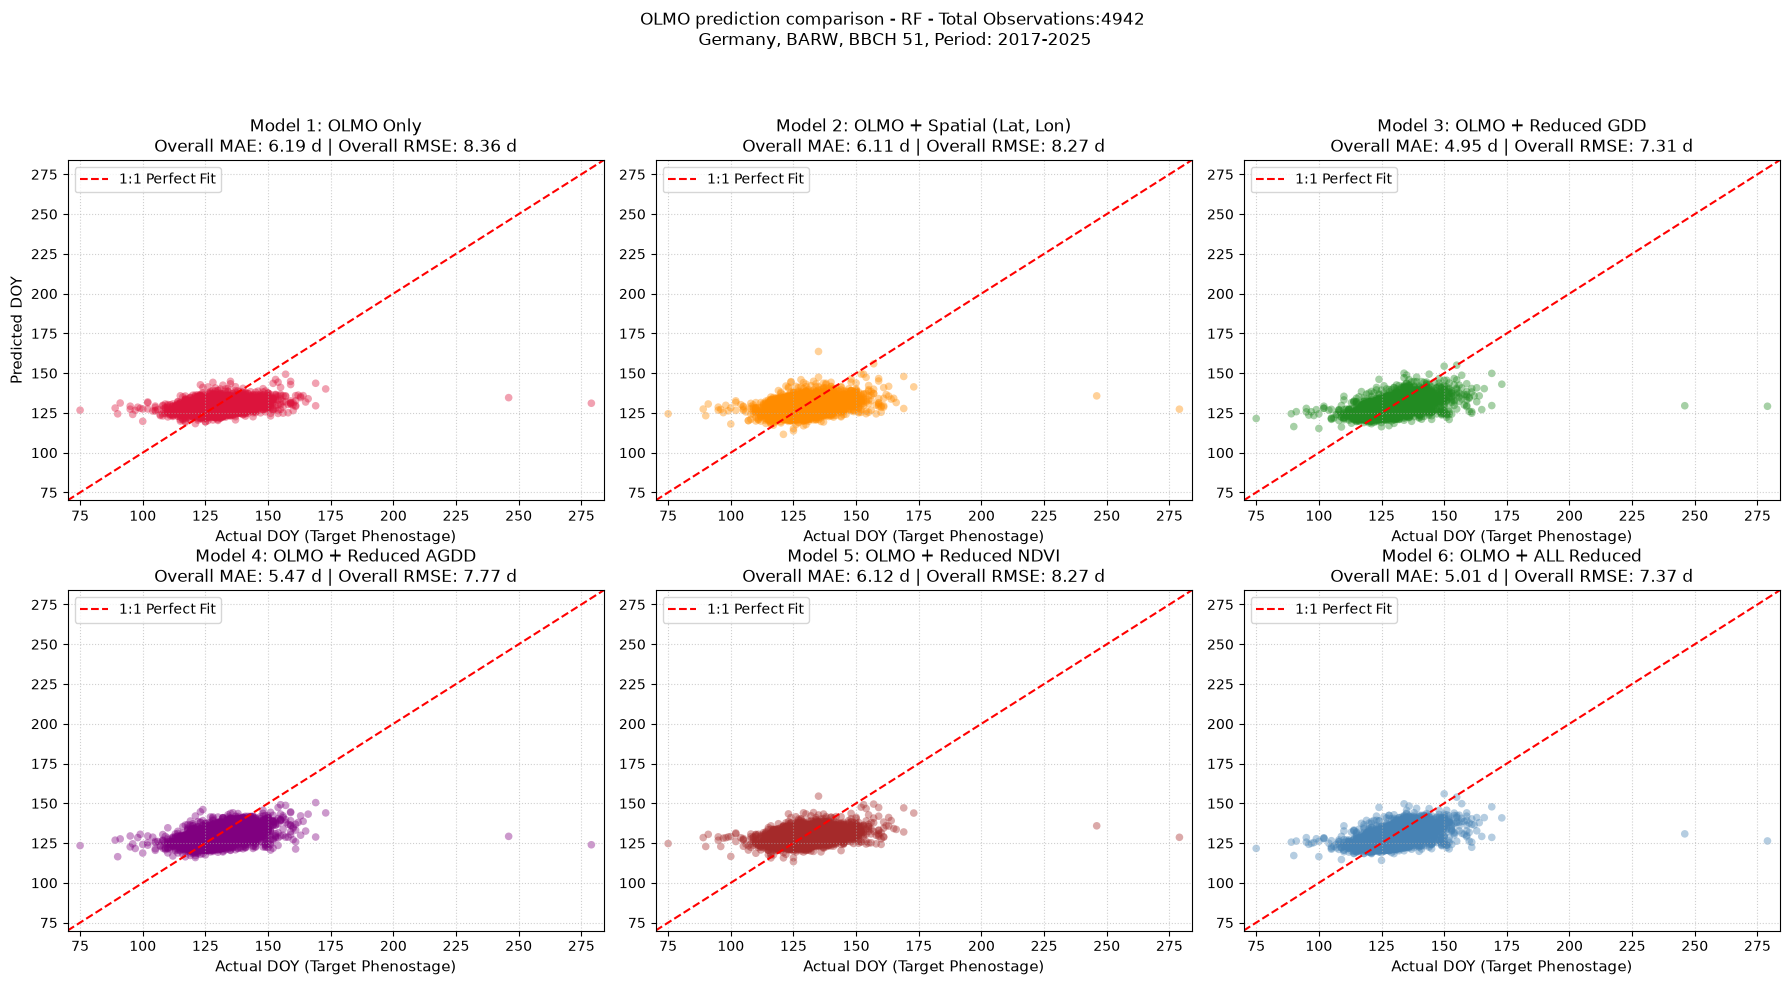

In [ ]:
plt.figure(figsize=(18, 10))
model_configs = [
    (f"Model 1: {model} Only", m1_preds, overall_m1_mae, overall_m1_rmse, "crimson"),
    (f"Model 2: {model} + Spatial (Lat, Lon)", m2_preds, overall_m2_mae, overall_m2_rmse, "darkorange"),
    (f"Model 3: {model} + Reduced GDD", m3_preds, overall_m3_mae, overall_m3_rmse, "forestgreen"),
    (f"Model 4: {model} + Reduced AGDD", m4_preds, overall_m4_mae, overall_m4_rmse, "purple"),
    (f"Model 5: {model} + Reduced NDVI", m5_preds, overall_m5_mae, overall_m5_rmse, "brown"),
    (f"Model 6: {model} + ALL Reduced", m6_preds, overall_m6_mae, overall_m6_rmse, "steelblue"),
]

min_val = min(actual_doy) - 5
max_val = max(actual_doy) + 5

for idx, (title, preds, mae_val, rmse_val, color) in enumerate(model_configs, start=1):
    plt.subplot(2, 3, idx)
    plt.scatter(actual_doy, preds, alpha=0.4, color=color, edgecolors="none", s=30)
    plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=1.5, label="1:1 Perfect Fit")
    
    plt.title(f"{title}\nOverall MAE: {mae_val:.2f} d | Overall RMSE: {rmse_val:.2f} d", fontsize=12)
    plt.xlabel("Actual DOY", fontsize=11)
    if idx == 1:
        plt.ylabel("Predicted DOY", fontsize=11)
        
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.suptitle(f"{model} prediction comparison - RF - Total Observations:{len(df_clean)} \n{final_name}")
plt.subplots_adjust(top=0.83)
plt.savefig(summary_save_path / f"scatter_comparison_{model.lower()}_rf_reduced.png", dpi=300)
plt.show()

### 3.9 $R^2$ Decomposition & Per-Year LOYOCV Trajectory Plots (Random Forest, Reduced Features)

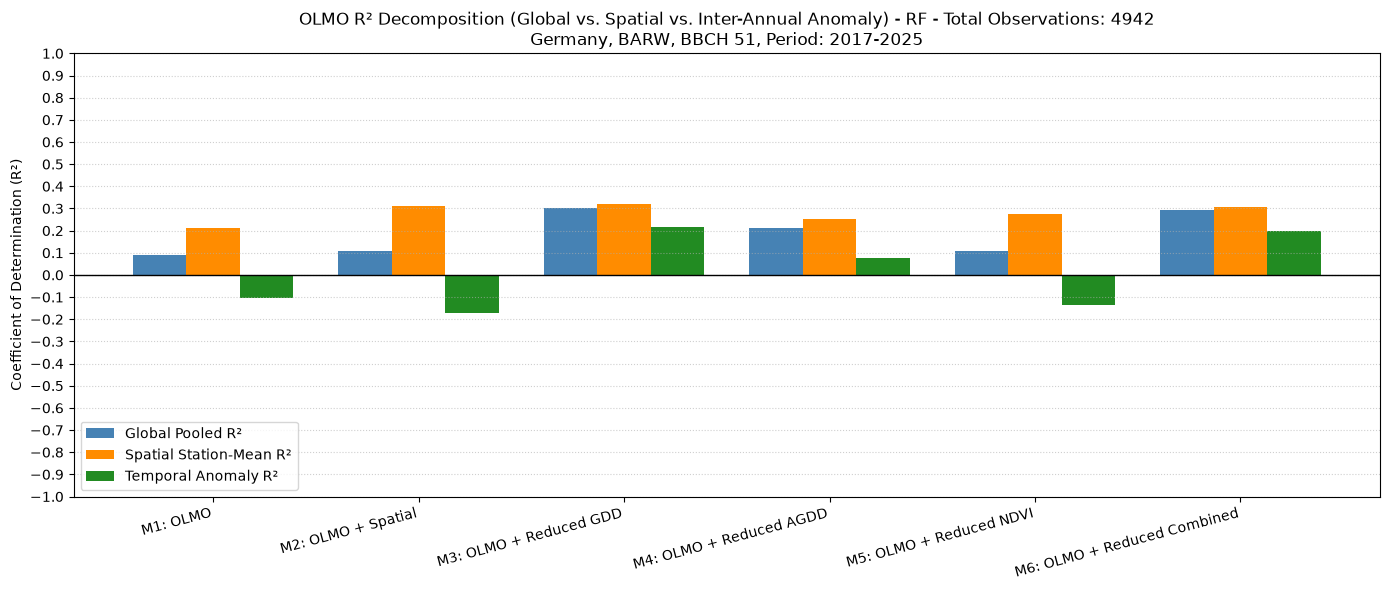

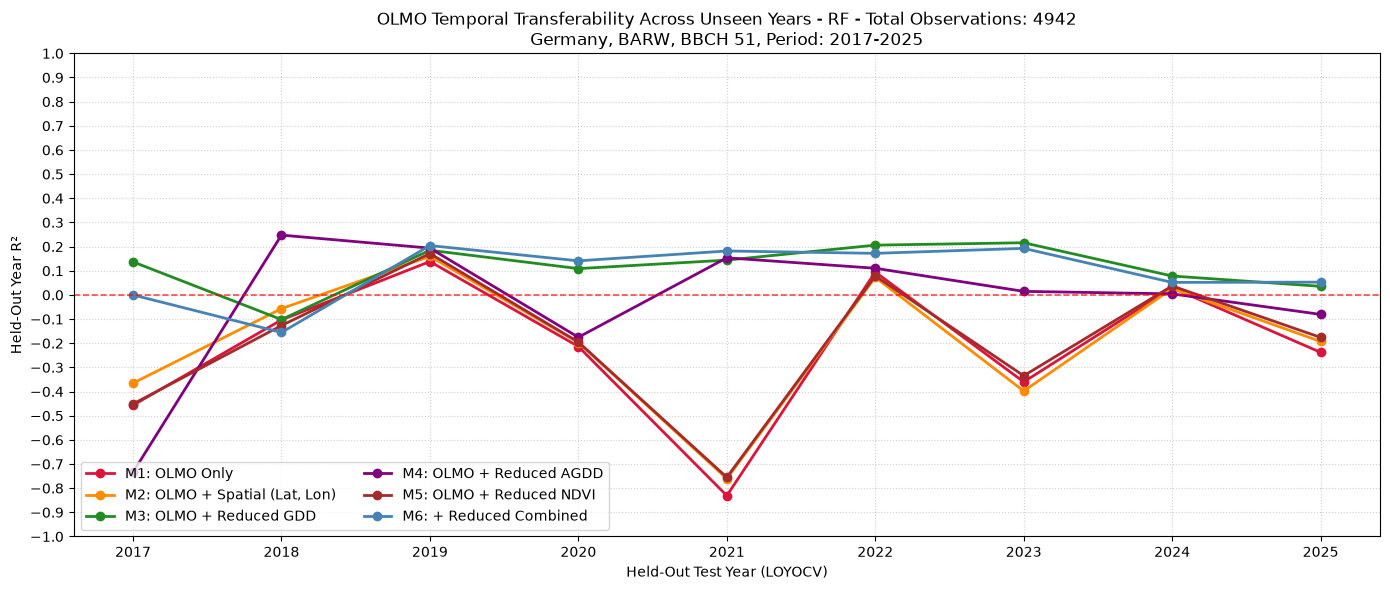

In [ ]:
from sklearn.metrics import r2_score

# Ensure actual_doy is a NumPy array for boolean masking
actual_doy_arr = np.asarray(actual_doy)

# Build station identifier from df_clean to separate spatial vs. temporal variance
if "PEP_ID" in df_clean.columns:
  station_ids = df_clean["PEP_ID"].values
else:
  station_ids = (
      df_clean["Latitude"].round(4).astype(str)
      + "_"
      + df_clean["Longitude"].round(4).astype(str)
  ).values

years_arr = df_clean["Year"].astype(int).values

rf_reduced_models = [
    (f"M1: {model} Only", np.asarray(m1_preds), "crimson"),
    (f"M2: {model} + Spatial (Lat, Lon)", np.asarray(m2_preds), "darkorange"),
    (f"M3: {model} + Reduced GDD", np.asarray(m3_preds), "forestgreen"),
    (f"M4: {model} + Reduced AGDD", np.asarray(m4_preds), "purple"),
    (f"M5: {model} + Reduced NDVI", np.asarray(m5_preds), "brown"),
    (
        "M6: + Reduced Combined",
        np.asarray(m6_preds),
        "steelblue",
    ),
]

# R² Decomposition Plot: Global vs. Spatial vs. Temporal Anomaly R² (RF)
global_r2_list = []
spatial_r2_list = []
temporal_r2_list = []
short_labels = [
    f"M1: {model}",
    f"M2: {model} + Spatial",
    f"M3: {model} + Reduced GDD",
    f"M4: {model} + Reduced AGDD",
    f"M5: {model} + Reduced NDVI",
    f"M6: {model} + Reduced Combined",
]

for _, preds, _ in rf_reduced_models:
  # 1. Global Pooled R²
  g_r2 = r2_score(actual_doy_arr, preds)

  # 2. Spatial Station-Mean R² & 3. Temporal Anomaly R² (ΔDOY)
  df_tmp = pd.DataFrame({
      "Station": station_ids,
      "Actual": actual_doy_arr,
      "Pred": preds,
  })
  st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
  s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

  df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
  obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
  pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
  t_r2 = r2_score(obs_anom, pred_anom)

  global_r2_list.append(g_r2)
  spatial_r2_list.append(s_r2)
  temporal_r2_list.append(t_r2)

# Save R² Decomposition values to CSV
df_r2_decomposition = pd.DataFrame({
    "Model_Key": [f"M{i}" for i in range(1, len(rf_reduced_models) + 1)],
    "Model_Label": short_labels,
    "Global_Pooled_R2": np.round(global_r2_list, 4),
    "Spatial_Station_Mean_R2": np.round(spatial_r2_list, 4),
    "Temporal_Anomaly_R2": np.round(temporal_r2_list, 4),
})
display(df_r2_decomposition)
df_r2_decomposition.to_csv(
    summary_save_path / f"r2_decomposition_{model.lower()}_rf_reduced.csv",
    sep=";",
    index=False,
)

x_pos = np.arange(len(rf_reduced_models))
bar_width = 0.26

plt.figure(figsize=(14, 6))
plt.bar(
    x_pos - bar_width,
    global_r2_list,
    width=bar_width,
    label="Global Pooled R²",
    color="steelblue",
)
plt.bar(
    x_pos,
    spatial_r2_list,
    width=bar_width,
    label="Spatial Station-Mean R²",
    color="darkorange",
)
plt.bar(
    x_pos + bar_width,
    temporal_r2_list,
    width=bar_width,
    label="Temporal Anomaly R²",
    color="forestgreen",
)

plt.axhline(0, color="black", lw=1.0)
plt.xticks(x_pos, short_labels, rotation=15, ha="right")
plt.yticks(y_ticks)
plt.ylabel("Coefficient of Determination (R²)")
plt.title(
    f"{model} R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) -"
    f" RF - Total Observations: {len(df_clean)}\n{final_name}"
)
plt.grid(True, axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="lower left", frameon=True)


plt.tight_layout()
plt.savefig(
    summary_save_path / f"r2_decomposition_{model.lower()}_rf_reduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Per-Year LOYOCV R² Trajectory Across Held-Out Years (RF Reduced)
unique_years = sorted(np.unique(years_arr))
df_r2_per_year = pd.DataFrame({"Test_Year": unique_years})

plt.figure(figsize=(14, 6))

for idx, (m_label, preds, color) in enumerate(rf_reduced_models, start=1):
  yearly_r2 = []
  for yr in unique_years:
    mask = years_arr == yr
    yearly_r2.append(r2_score(actual_doy_arr[mask], preds[mask]))

  df_r2_per_year[f"M{idx}_R2"] = np.round(yearly_r2, 4)

  plt.plot(
      unique_years,
      yearly_r2,
      marker="o",
      lw=2,
      color=color,
      label=m_label,
  )

# Save Per-Year R² values to CSV
display(df_r2_per_year)
df_r2_per_year.to_csv(
    summary_save_path / f"r2_per_year_{model.lower()}_rf_reduced.csv",
    sep=";",
    index=False,
)

plt.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
plt.title(
    f"{model} Temporal Transferability Across Unseen Years - RF - Total"
    f" Observations: {len(df_clean)}\n{final_name}"
)
plt.xlabel("Held-Out Test Year (LOYOCV)")
plt.ylabel("Held-Out Year R²")
plt.yticks(y_ticks)
plt.xticks(unique_years)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", ncol=2, frameon=True)


plt.tight_layout()
plt.savefig(
    summary_save_path / f"r2_per_year_{model.lower()}_rf_reduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### 3.10 LOYOCV Hyperparameter Search (XGBoost, Reduced Features)

In [52]:
# Hyperparameter search space for XGBoost models
print("=" * 80)
print("RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1 TO 6 (XGBOOST)")
print("=" * 80)

for model_key, feat_cols in models_to_tune.items():
    print(f"\nTuning {model_key} (Total Features: {len(feat_cols)})...")

    X_subset = df_reduced[feat_cols]

    # Adapt feature subsampling ratio to feature space size
    if len(feat_cols) <= 3:
        colsample_dist = [1.0]
    else:
        colsample_dist = uniform(0.30, 0.50)  # Randomly samples between 30% and 80%

    xgb_param_distributions = {
        # Ensemble size and shrinkage
        "n_estimators": randint(150, 350),
        "learning_rate": uniform(0.02, 0.08),  # Range: 0.02 to 0.10
        # Tree architecture (keep shallow for small N)
        "max_depth": randint(3, 6),            # Depths 3, 4, 5
        "min_child_weight": randint(2, 7),     # Analogous to min_samples_leaf (2 to 6)
        "gamma": uniform(0.0, 1.5),            # Minimum loss reduction for a split
        # Stochastic sampling
        "subsample": uniform(0.65, 0.30),      # Row subsampling (0.65 to 0.95)
        "colsample_bytree": colsample_dist,    # Column subsampling
        # Regularization
        "reg_alpha": [0.0, 0.1, 1.0],
        "reg_lambda": [1.0, 3.0, 8.0],
    }

    xgb_search = RandomizedSearchCV(
        estimator=XGBRegressor(
            objective="reg:squarederror",
            eval_metric="mae",
            random_state=42,
            n_jobs=1,  # Keep inner booster single-threaded
        ),
        param_distributions=xgb_param_distributions,
        n_iter=25,
        scoring="neg_mean_absolute_error",
        cv=logo,
        random_state=42,
        n_jobs=-1,  # Parallelize across CV folds/iterations
        verbose=0,
    )

    # Fit using groups to enforce Leave-One-Year-Out validation
    xgb_search.fit(X_subset, y_all, groups=groups_all)

    best_params_dict[model_key] = xgb_search.best_params_
    print(f" -> Best LOYOCV MAE: {-xgb_search.best_score_:.2f} days")
    print(f" -> Optimal Parameters: {xgb_search.best_params_}")

# Prediction lists for pooled evaluation
m1_preds = []
m2_preds = []
m3_preds = []
m4_preds = []
m5_preds = []
m6_preds = []
actual_doy = []
test_years_list = []
fold_results = []

print(
    f"Model 1 ({model} Only):        "
    f" {len(features_m1_embedding_only)} features"
)
print(
    f"Model 2 ({model} + Spatial):   "
    f" {len(features_m2_embedding_spatial)} features"
)
print(
    f"Model 3 ({model} + GDD ):      "
    f" {len(features_m3_embedding_GDD)} features"
)
print(
    f"Model 4 ({model} + AGDD):      "
    f" {len(features_m4_embedding_AGDD)} features"
)
print(
    f"Model 5 ({model} + NDVI):     "
    f" {len(features_m5_embedding_NDVI)} features"
)
print(
    f"Model 6 ({model} + ALL):      "
    f" {len(features_m6_embedding_all)} features"
)
print(f"Total LOYOCV folds:            {len(unique_years)} years")

RUNNING LOYOCV HYPERPARAMETER SEARCH FOR MODELS 1 TO 6 (XGBOOST)

Tuning M1 (Total Features: 128)...
 -> Best LOYOCV MAE: 6.18 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.7541329429833268), 'gamma': np.float64(0.35934283600045863), 'learning_rate': np.float64(0.03159158976729785), 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 332, 'reg_alpha': 1.0, 'reg_lambda': 8.0, 'subsample': np.float64(0.7226479814832278)}

Tuning M2 (Total Features: 130)...
 -> Best LOYOCV MAE: 6.15 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.4743329936458647), 'gamma': np.float64(0.14426482663713114), 'learning_rate': np.float64(0.09524186115916833), 'max_depth': 5, 'min_child_weight': 3, 'n_estimators': 253, 'reg_alpha': 0.0, 'reg_lambda': 8.0, 'subsample': np.float64(0.7523199053150775)}

Tuning M3 (Total Features: 142)...
 -> Best LOYOCV MAE: 5.00 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.7934434683002587), 'gamma': np.float64(1.1583671539449

### 3.11 Run LOYOCV Evaluation (XGBoost, Reduced Features)

In [53]:
print(f"Starting LOYOCV across {len(unique_years)} folds...\n")

for test_year in unique_years:
    train_mask = df_reduced["Year"] != test_year
    test_mask = df_reduced["Year"] == test_year
    y_train = df_reduced.loc[train_mask, "DOY"]
    y_test = df_reduced.loc[test_mask, "DOY"]

    # --- Model 1: TESSERA only ---
    xgb_m1 = XGBRegressor(
        **best_params_dict["M1"], random_state=42, n_jobs=-1
    )
    xgb_m1.fit(
        df_reduced.loc[train_mask, features_m1_embedding_only], y_train
    )
    pred_m1 = xgb_m1.predict(
        df_reduced.loc[test_mask, features_m1_embedding_only]
    )

    # --- Model 2: TESSERA & Lat/Lon ---
    xgb_m2 = XGBRegressor(
        **best_params_dict["M2"], random_state=42, n_jobs=-1
    )
    xgb_m2.fit(
        df_reduced.loc[train_mask, features_m2_embedding_spatial], y_train
    )
    pred_m2 = xgb_m2.predict(
        df_reduced.loc[test_mask, features_m2_embedding_spatial]
    )

    # --- Model 3: TESSERA & GDD ---
    xgb_m3 = XGBRegressor(
        **best_params_dict["M3"], random_state=42, n_jobs=-1
    )
    xgb_m3.fit(
        df_reduced.loc[train_mask, features_m3_embedding_GDD], y_train
    )
    pred_m3 = xgb_m3.predict(
        df_reduced.loc[test_mask, features_m3_embedding_GDD]
    )

    # --- Model 4: TESSERA & AGDD ---
    xgb_m4 = XGBRegressor(
        **best_params_dict["M4"], random_state=42, n_jobs=-1
    )
    xgb_m4.fit(
        df_reduced.loc[train_mask, features_m4_embedding_AGDD], y_train
    )
    pred_m4 = xgb_m4.predict(
        df_reduced.loc[test_mask, features_m4_embedding_AGDD]
    )

    # --- Model 5: Combined Multimodal ---
    xgb_m5 = XGBRegressor(
        **best_params_dict["M5"], random_state=42, n_jobs=-1
    )
    xgb_m5.fit(
        df_reduced.loc[train_mask, features_m5_embedding_NDVI], y_train
    )
    pred_m5 = xgb_m5.predict(
        df_reduced.loc[test_mask, features_m5_embedding_NDVI]
    )

    # --- Model 6: Combined Multimodal ---
    xgb_m6 = XGBRegressor(
        **best_params_dict["M6"], random_state=42, n_jobs=-1  
    )
    xgb_m6.fit(
        df_reduced.loc[train_mask, features_m6_embedding_all], y_train
        )
    pred_m6 = xgb_m6.predict(
        df_reduced.loc[test_mask, features_m6_embedding_all]
    )
    
    # Fold metrics
    mae_m1 = mean_absolute_error(y_test, pred_m1)
    rmse_m1 = np.sqrt(mean_squared_error(y_test, pred_m1))

    mae_m2 = mean_absolute_error(y_test, pred_m2)
    rmse_m2 = np.sqrt(mean_squared_error(y_test, pred_m2))

    mae_m3 = mean_absolute_error(y_test, pred_m3)
    rmse_m3 = np.sqrt(mean_squared_error(y_test, pred_m3))

    mae_m4 = mean_absolute_error(y_test, pred_m4)
    rmse_m4 = np.sqrt(mean_squared_error(y_test, pred_m4))

    mae_m5 = mean_absolute_error(y_test, pred_m5)
    rmse_m5 = np.sqrt(mean_squared_error(y_test, pred_m5))

    mae_m6 = mean_absolute_error(y_test, pred_m6)
    rmse_m6 = np.sqrt(mean_squared_error(y_test, pred_m6))

    fold_results.append(
    {
        "Test_Year": test_year,
        "N_Samples": len(y_test),
        f"M1_{model}_MAE": round(mae_m1, 2),
        f"M1_{model}_RMSE": round(rmse_m1, 2),
        f"M2_{model}_LatLon_MAE": round(mae_m2, 2),
        f"M2_{model}_LatLon_RMSE": round(rmse_m2, 2),
        f"M3_{model}_GDD_MAE": round(mae_m3, 2),
        f"M3_{model}_GDD_RMSE": round(rmse_m3, 2),
        f"M4_{model}_AGDD_MAE": round(mae_m4, 2),
        f"M4_{model}_AGDD_RMSE": round(rmse_m4, 2),
        f"M5_{model}_NDVI_MAE": round(mae_m5, 2),
        f"M5_{model}_NDVI_RMSE": round(rmse_m5, 2),
        f"M6_{model}_Combined_MAE": round(mae_m6, 2),
        f"M6_{model}_Combined_RMSE": round(rmse_m6, 2),
    }
    )

    m1_preds.extend(pred_m1)
    m2_preds.extend(pred_m2)
    m3_preds.extend(pred_m3)
    m4_preds.extend(pred_m4)
    m5_preds.extend(pred_m5)
    m6_preds.extend(pred_m6)
    actual_doy.extend(y_test.values)
    test_years_list.extend([test_year] * len(y_test))

    print(
        f"Year {test_year} (N={len(y_test):3d}) "
        f"M1 ({model}) MAE: {mae_m1:5.2f} d "
        f"M2 ({model} + Lat/Lon) MAE: {mae_m2:5.2f} d "
        f"M3 ({model} + GDD) MAE: {mae_m3:5.2f} d "
        f"M4 ({model} + AGDD) MAE: {mae_m4:5.2f} d "
        f"M5 ({model} + NDVI) MAE: {mae_m5:5.2f} d "
        f"M6 Combined MAE: {mae_m6:5.2f} d "
    )

print("\nLOYOCV evaluation finished!")


Starting LOYOCV across 9 folds...

Year 2017 (N=621) M1 (OLMO) MAE:  5.81 d M2 (OLMO + Lat/Lon) MAE:  5.54 d M3 (OLMO + GDD) MAE:  4.05 d M4 (OLMO + AGDD) MAE:  6.51 d M5 (OLMO + NDVI) MAE:  5.79 d M6 Combined MAE:  4.51 d 
Year 2018 (N=598) M1 (OLMO) MAE:  5.31 d M2 (OLMO + Lat/Lon) MAE:  5.14 d M3 (OLMO + GDD) MAE:  5.12 d M4 (OLMO + AGDD) MAE:  4.05 d M5 (OLMO + NDVI) MAE:  5.35 d M6 Combined MAE:  5.29 d 
Year 2019 (N=592) M1 (OLMO) MAE:  5.80 d M2 (OLMO + Lat/Lon) MAE:  5.76 d M3 (OLMO + GDD) MAE:  5.54 d M4 (OLMO + AGDD) MAE:  5.65 d M5 (OLMO + NDVI) MAE:  5.68 d M6 Combined MAE:  5.52 d 
Year 2020 (N=579) M1 (OLMO) MAE:  6.24 d M2 (OLMO + Lat/Lon) MAE:  6.18 d M3 (OLMO + GDD) MAE:  5.05 d M4 (OLMO + AGDD) MAE:  6.22 d M5 (OLMO + NDVI) MAE:  6.15 d M6 Combined MAE:  4.93 d 
Year 2021 (N=543) M1 (OLMO) MAE:  8.12 d M2 (OLMO + Lat/Lon) MAE:  7.96 d M3 (OLMO + GDD) MAE:  4.82 d M4 (OLMO + AGDD) MAE:  4.78 d M5 (OLMO + NDVI) MAE:  7.92 d M6 Combined MAE:  4.66 d 
Year 2022 (N=529) M1

### 3.12 Summarize, Save & Scatter Plots (XGBoost, Reduced Features)


OVERALL LOYOCV BENCHMARK RESULTS (germany_barw_bbch51_2017-01-01_2025-12-31)
Model 1: OLMO --> Overall MAE:  6.19 days | Overall RMSE: 8.36 days
Model 2: OLMO + Spatial (Lat, Lon) --> Overall MAE:  6.11 days | Overall RMSE: 8.27 days
Model 3: OLMO + Reduced 12M GDD + Stress Fusion --> Overall MAE:  4.95 days | Overall RMSE: 7.31 days
Model 4: OLMO + Reduced 26-Step AGDD Fusion --> Overall MAE:  5.47 days | Overall RMSE: 7.77 days
Model 5: OLMO + Reduced NDVI Fusion --> Overall MAE:  6.12 days | Overall RMSE: 8.27 days
Model 6: OLMO + ALL --> Overall MAE:  5.01 days | Overall RMSE: 7.37 days


,Test_Year,N_Samples,M1_OLMO_MAE,M1_OLMO_RMSE,M2_OLMO_LatLon_MAE,M2_OLMO_LatLon_RMSE,M3_OLMO_GDD_MAE,M3_OLMO_GDD_RMSE,M4_OLMO_AGDD_MAE,M4_OLMO_AGDD_RMSE,M5_OLMO_NDVI_MAE,M5_OLMO_NDVI_RMSE,M6_OLMO_Combined_MAE,M6_OLMO_Combined_RMSE
0,2017,621,5.81,7.31,5.54,7.08,4.05,5.63,6.51,7.98,5.79,7.30,4.51,6.06
1,2018,598,5.31,6.78,5.14,6.64,5.12,6.78,4.05,5.60,5.35,6.85,5.29,6.94
2,2019,592,5.80,7.77,5.76,7.68,5.54,7.56,5.65,7.52,5.68,7.62,5.52,7.47
3,2020,579,6.24,7.79,6.18,7.73,5.05,6.67,6.22,7.66,6.15,7.73,4.93,6.55
4,2021,543,8.12,9.86,7.96,9.67,4.82,6.74,4.78,6.71,7.92,9.66,4.66,6.59
5,2022,529,4.44,6.05,4.63,6.13,4.12,5.67,4.33,6.00,4.59,6.11,4.22,5.79
6,2023,511,5.65,7.39,5.78,7.49,3.86,5.61,4.55,6.29,5.62,7.32,3.93,5.69
7,2024,488,6.60,11.64,6.55,11.66,5.43,11.34,5.81,11.79,6.56,11.59,5.52,11.50
8,2025,481,8.08,9.91,7.84,9.73,6.74,8.75,7.45,9.26,7.78,9.66,6.61,8.67


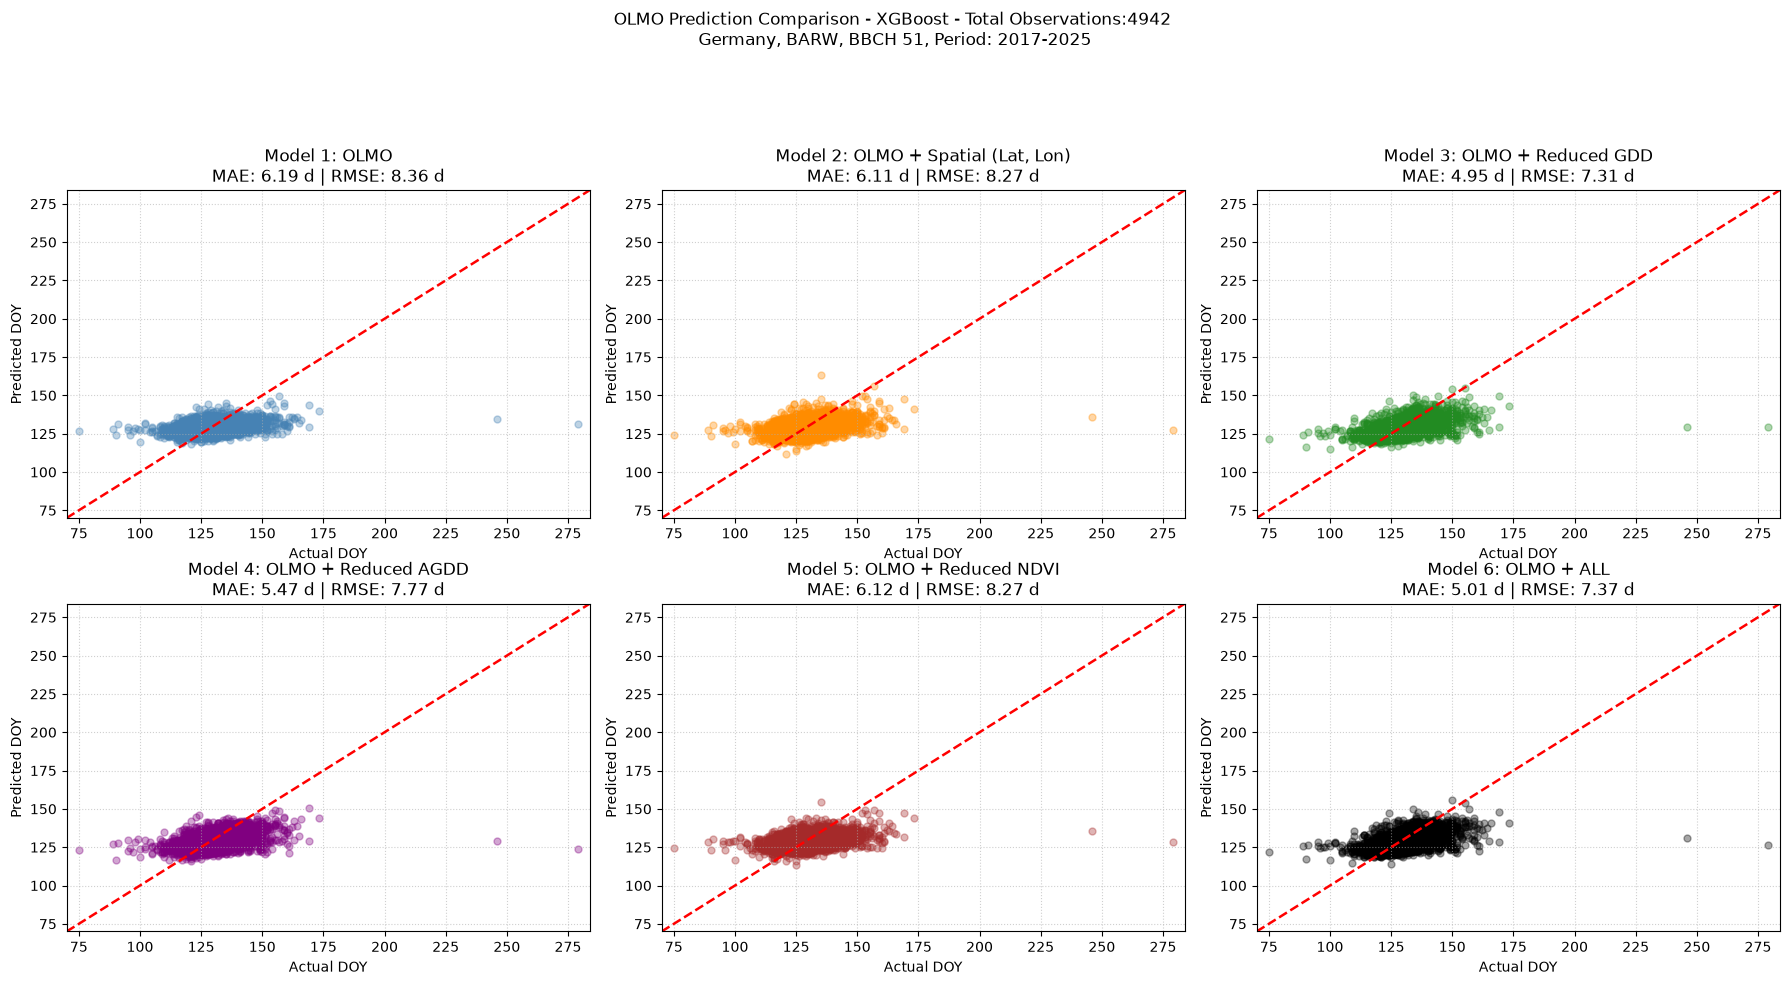

In [81]:
df_folds = pd.DataFrame(fold_results)

overall_m1_mae = mean_absolute_error(actual_doy, m1_preds)
overall_m1_rmse = np.sqrt(mean_squared_error(actual_doy, m1_preds))
overall_m2_mae = mean_absolute_error(actual_doy, m2_preds)
overall_m2_rmse = np.sqrt(mean_squared_error(actual_doy, m2_preds))
overall_m3_mae = mean_absolute_error(actual_doy, m3_preds)
overall_m3_rmse = np.sqrt(mean_squared_error(actual_doy, m3_preds))
overall_m4_mae = mean_absolute_error(actual_doy, m4_preds)
overall_m4_rmse = np.sqrt(mean_squared_error(actual_doy, m4_preds))
overall_m5_mae = mean_absolute_error(actual_doy, m5_preds)
overall_m5_rmse = np.sqrt(mean_squared_error(actual_doy, m5_preds))
overall_m6_mae = mean_absolute_error(actual_doy, m6_preds)
overall_m6_rmse = np.sqrt(mean_squared_error(actual_doy, m6_preds))

# Print overall results
print(f"\n{'='*80}")
print(f"OVERALL LOYOCV BENCHMARK RESULTS ({selected_folder.name})")
print(f"{'='*80}")
print(f"Model 1: {model} --> Overall MAE:  {overall_m1_mae:.2f} days | Overall RMSE: {overall_m1_rmse:.2f} days")
print(f"Model 2: {model} + Spatial (Lat, Lon) --> Overall MAE:  {overall_m2_mae:.2f} days | Overall RMSE: {overall_m2_rmse:.2f} days")
print(f"Model 3: {model} + Reduced 12M GDD + Stress Fusion --> Overall MAE:  {overall_m3_mae:.2f} days | Overall RMSE: {overall_m3_rmse:.2f} days")
print(f"Model 4: {model} + Reduced 26-Step AGDD Fusion --> Overall MAE:  {overall_m4_mae:.2f} days | Overall RMSE: {overall_m4_rmse:.2f} days")
print(f"Model 5: {model} + Reduced NDVI Fusion --> Overall MAE:  {overall_m5_mae:.2f} days | Overall RMSE: {overall_m5_rmse:.2f} days")
print(f"Model 6: {model} + ALL --> Overall MAE:  {overall_m6_mae:.2f} days | Overall RMSE: {overall_m6_rmse:.2f} days")

display(df_folds)

results_path_filtered = summary_save_path / f"{model.lower()}_loyocv_results_xgboost_reduced.csv"
df_folds.to_csv(results_path_filtered, sep=";", index=False)

# Scatter plots for the 5 baselines 
plt.figure(figsize=(18, 10))

models_plot = [
    (f"Model 1: {model}", m1_preds, overall_m1_mae, overall_m1_rmse, "steelblue"),
    (f"Model 2: {model} + Spatial (Lat, Lon)", m2_preds, overall_m2_mae, overall_m2_rmse, "darkorange"),
    (f"Model 3: {model} + Reduced GDD", m3_preds, overall_m3_mae, overall_m3_rmse, "forestgreen"),
    (f"Model 4: {model} + Reduced AGDD", m4_preds, overall_m4_mae, overall_m4_rmse, "purple"),
    (f"Model 5: {model} + Reduced NDVI", m5_preds, overall_m5_mae, overall_m5_rmse, "brown"),
    (f"Model 6: {model} + ALL", m6_preds, overall_m6_mae, overall_m6_rmse, "black")]

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot, 1):
    plt.subplot(2, 3, i)
    plt.scatter(actual_doy, predictions, alpha=0.35, color=color, s=25)
    plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=1.8, label="1:1 Fit")
    plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d")
    plt.xlabel("Actual DOY")
    plt.ylabel("Predicted DOY")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)

plt.tight_layout()
plt.subplots_adjust(top=0.8)
plt.suptitle(f"{model} Prediction Comparison - XGBoost - Total Observations:{len(df_clean)} \n{final_name}")
# Save plot
plt.savefig(summary_save_path / f"scatter_comparison_{model.lower()}_xgboost_reduced", dpi=300, bbox_inches="tight")
plt.show()

### 3.13 $R^2$ Decomposition & Per-Year LOYOCV Trajectory Plots (XGBoost, Reduced Features)

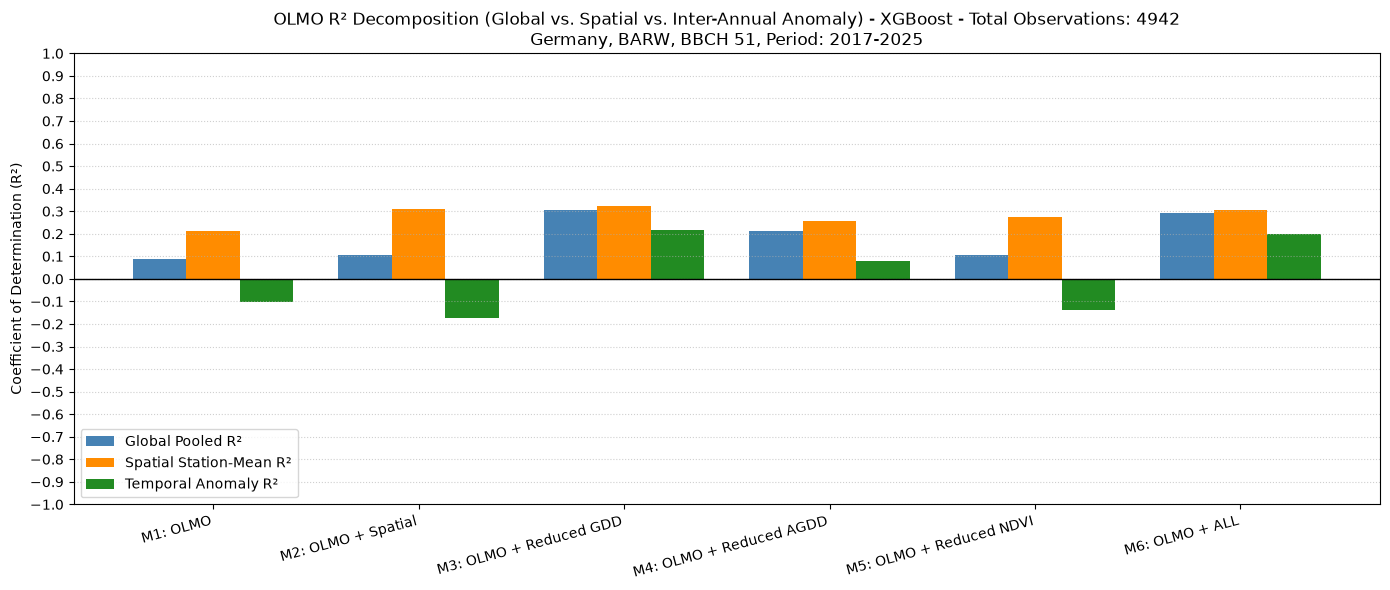

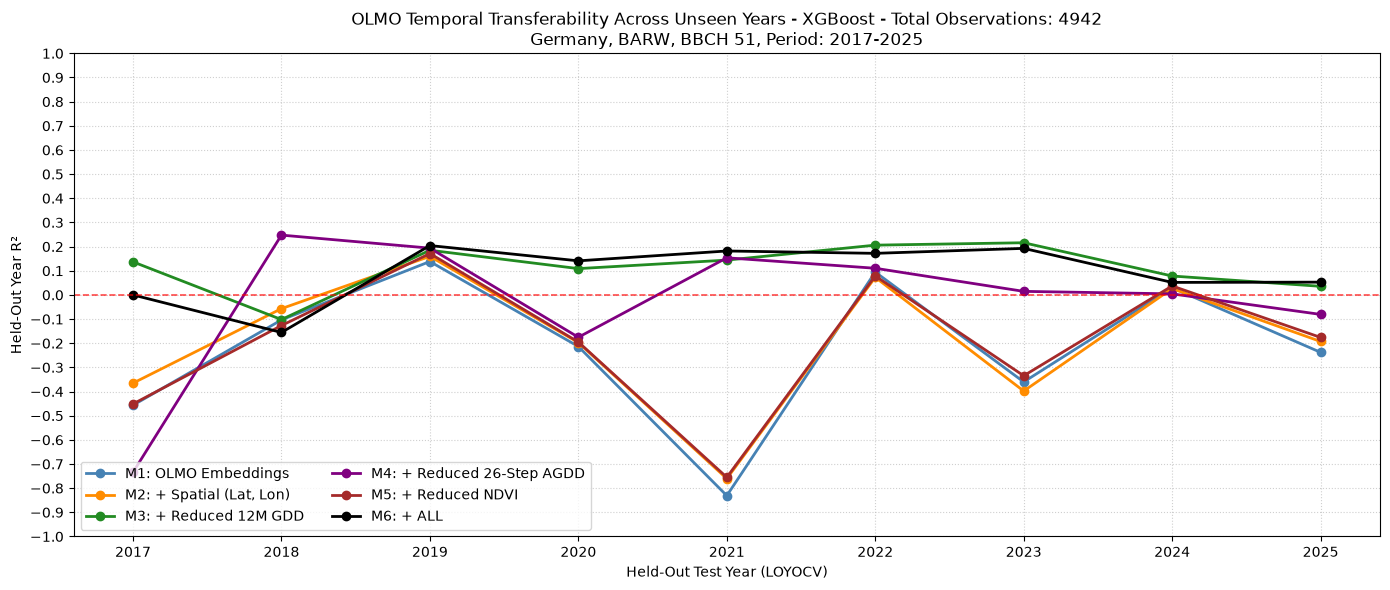

In [83]:
from sklearn.metrics import r2_score

# Ensure actual_doy is a NumPy array for boolean masking
actual_doy_arr = np.asarray(actual_doy)

# Build station identifier from df_clean to separate spatial vs. temporal variance
if "PEP_ID" in df_clean.columns:
  station_ids = df_clean["PEP_ID"].values
else:
  station_ids = (
      df_clean["Latitude"].round(4).astype(str)
      + "_"
      + df_clean["Longitude"].round(4).astype(str)
  ).values

years_arr = df_clean["Year"].astype(int).values

xgb_reduced_models = [
    (f"M1: {model} Embeddings", np.asarray(m1_preds), "steelblue"),
    ("M2: + Spatial (Lat, Lon)", np.asarray(m2_preds), "darkorange"),
    ("M3: + Reduced 12M GDD", np.asarray(m3_preds), "forestgreen"),
    ("M4: + Reduced 26-Step AGDD", np.asarray(m4_preds), "purple"),
    ("M5: + Reduced NDVI", np.asarray(m5_preds), "brown"),
    ("M6: + ALL", np.asarray(m6_preds), "black"),
]

# R² Decomposition Plot: Global vs. Spatial vs. Temporal Anomaly R²
global_r2_list = []
spatial_r2_list = []
temporal_r2_list = []
short_labels = [
    f"M1: {model}",
    f"M2: {model} + Spatial",
    f"M3: {model} + Reduced GDD",
    f"M4: {model} + Reduced AGDD",
    f"M5: {model} + Reduced NDVI",
    f"M6: {model} + ALL",
]

for _, preds, _ in xgb_reduced_models:
  # 1. Global Pooled R²
  g_r2 = r2_score(actual_doy_arr, preds)

  # 2. Spatial Station-Mean R² & 3. Temporal Anomaly R² (ΔDOY)
  df_tmp = pd.DataFrame({
      "Station": station_ids,
      "Actual": actual_doy_arr,
      "Pred": preds,
  })
  st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
  s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

  df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
  obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
  pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
  t_r2 = r2_score(obs_anom, pred_anom)

  global_r2_list.append(g_r2)
  spatial_r2_list.append(s_r2)
  temporal_r2_list.append(t_r2)

# Save R² Decomposition values to CSV
df_r2_decomposition = pd.DataFrame({
    "Model_Key": [f"M{i}" for i in range(1, len(xgb_reduced_models) + 1)],
    "Model_Label": short_labels,
    "Global_Pooled_R2": np.round(global_r2_list, 4),
    "Spatial_Station_Mean_R2": np.round(spatial_r2_list, 4),
    "Temporal_Anomaly_R2": np.round(temporal_r2_list, 4),
})
display(df_r2_decomposition)
df_r2_decomposition.to_csv(
    summary_save_path / f"r2_decomposition_{model.lower()}_xgboost_reduced.csv",
    sep=";",
    index=False,
)

x_pos = np.arange(len(xgb_reduced_models))
bar_width = 0.26

plt.figure(figsize=(14, 6))
plt.bar(
    x_pos - bar_width,
    global_r2_list,
    width=bar_width,
    label="Global Pooled R²",
    color="steelblue",
)
plt.bar(
    x_pos,
    spatial_r2_list,
    width=bar_width,
    label="Spatial Station-Mean R²",
    color="darkorange",
)
plt.bar(
    x_pos + bar_width,
    temporal_r2_list,
    width=bar_width,
    label="Temporal Anomaly R²",
    color="forestgreen",
)

plt.axhline(0, color="black", lw=1.0)
plt.xticks(x_pos, short_labels, rotation=15, ha="right")
plt.yticks(y_ticks)
plt.ylabel("Coefficient of Determination (R²)")
plt.title(
    f"{model} R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) -"
    f" XGBoost - Total Observations: {len(df_clean)}\n{final_name}"
)
plt.grid(True, axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="lower left", frameon=True)

plt.tight_layout()
plt.savefig(
    summary_save_path / f"r2_decomposition_{model.lower()}_xgboost_reduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Per-Year LOYOCV R² Trajectory Across Held-Out Years (M1 to M6)
unique_years = sorted(np.unique(years_arr))
df_r2_per_year = pd.DataFrame({"Test_Year": unique_years})

plt.figure(figsize=(14, 6))

for idx, (m_label, preds, color) in enumerate(xgb_reduced_models, start=1):
  yearly_r2 = []
  for yr in unique_years:
    mask = years_arr == yr
    yearly_r2.append(r2_score(actual_doy_arr[mask], preds[mask]))

  df_r2_per_year[f"M{idx}_R2"] = np.round(yearly_r2, 4)

  plt.plot(
      unique_years,
      yearly_r2,
      marker="o",
      lw=2,
      color=color,
      label=m_label,
  )

# Save Per-Year R² values to CSV
display(df_r2_per_year)
df_r2_per_year.to_csv(
    summary_save_path / f"r2_per_year_{model.lower()}_xgboost_reduced.csv",
    sep=";",
    index=False,
)

plt.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
plt.title(
    f"{model} Temporal Transferability Across Unseen Years - XGBoost - Total"
    f" Observations: {len(df_clean)}\n{final_name}"
)
plt.xlabel("Held-Out Test Year (LOYOCV)")
plt.ylabel("Held-Out Year R²")
plt.yticks(y_ticks)
plt.xticks(unique_years)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    summary_save_path / f"r2_per_year_{model.lower()}_xgboost_reduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## Part 4: PCA-Reduced FM Embeddings (`24-d`) + Domain-Reduced Features (Random Forest & XGBoost)
### 4.1 Configure PCA Components & Model Feature Sets

In [56]:
# Number of PCA components for model embeddings
N_PCA_COMPONENTS = 24

baselines = {
    "M1" : [],
    "M2" : ["Latitude", "Longitude"],
    "M3" : [c for c in df_reduced.columns if c.startswith("GDD_")],
    "M4" : [c for c in df_reduced.columns if c.startswith("AGDD_")],
    "M5" : [c for c in df_reduced.columns if c.startswith("NDVI_") or c.startswith("ANDVI_")],
    "M6" : ["Latitude", "Longitude"] + [c for c in df_reduced.columns if c.startswith("GDD_")] + 
    [c for c in df_reduced.columns if c.startswith("AGDD_")] + [c for c in df_reduced.columns if c.startswith("NDVI_") or c.startswith("ANDVI_")]
}

unique_years = sorted(df_reduced["Year"].unique())
y_all = df_reduced["DOY"]
groups_all = df_reduced["Year"]

### 4.2 Leak-Free Pipeline LOYOCV Hyperparameter Search (Random Forest & XGBoost)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("=" * 80)
print(
    f"RUNNING LOYOCV TUNING (PCA N={N_PCA_COMPONENTS}) FOR RF &"
    " XGBOOST"
)
print("=" * 80)

logo = LeaveOneGroupOut()
best_params_rf = {}
best_params_xgb = {}

for model_key, extra_cols in baselines.items():
  print(f"\n--- Tuning {model_key} ---")

  all_cols = embedding_cols + extra_cols
  X_subset = df_reduced[all_cols]

  # Preprocessor: Standardize & reduce TESSERA; pass other features untouched
  preprocessor = ColumnTransformer(
      transformers=[
          (
              "tessera_pca",
              Pipeline([
                  ("scaler", StandardScaler()),
                  ("pca", PCA(n_components=N_PCA_COMPONENTS, random_state=42)),
              ]),
              embedding_cols,
          ),
          ("passthrough", "passthrough", extra_cols),
      ]
  )

  # 1. Random Forest Tuning Pipeline
  rf_pipeline = Pipeline([
      ("prep", preprocessor),
      ("rf", RandomForestRegressor(random_state=42, n_jobs=-1)),
  ])

  rf_param_dist = {
      "rf__n_estimators": randint(150, 350),
      "rf__max_depth": [None, 10, 15, 20],
      "rf__min_samples_leaf": randint(1, 5),
      "rf__min_samples_split": randint(2, 6),
      "rf__max_features": uniform(0.25, 0.50),
  }

  rf_search = RandomizedSearchCV(
      estimator=rf_pipeline,
      param_distributions=rf_param_dist,
      n_iter=15,
      scoring="neg_mean_absolute_error",
      cv=logo,
      random_state=42,
      n_jobs=-1,
      verbose=0,
  )
  rf_search.fit(X_subset, y_all, groups=groups_all)
  best_params_rf[model_key] = {
      k.replace("rf__", ""): v for k, v in rf_search.best_params_.items()
  }
  print(f" -> Best RF LOYOCV MAE: {-rf_search.best_score_:.2f} days")

  # 2. XGBoost Tuning Pipeline
  xgb_pipeline = Pipeline([
      ("prep", preprocessor),
      (
          "xgb",
          XGBRegressor(
              random_state=42,
              n_jobs=-1,
              tree_method="hist",
          ),
      ),
  ])

  xgb_param_dist = {
      "xgb__n_estimators": randint(100, 300),
      "xgb__max_depth": randint(3, 8),
      "xgb__learning_rate": uniform(0.01, 0.08),
      "xgb__subsample": uniform(0.6, 0.4),
      "xgb__colsample_bytree": uniform(0.5, 0.5),
  }

  xgb_search = RandomizedSearchCV(
      estimator=xgb_pipeline,
      param_distributions=xgb_param_dist,
      n_iter=15,
      scoring="neg_mean_absolute_error",
      cv=logo,
      random_state=42,
      n_jobs=-1,
      verbose=0,
  )
  xgb_search.fit(X_subset, y_all, groups=groups_all)
  best_params_xgb[model_key] = {
      k.replace("xgb__", ""): v for k, v in xgb_search.best_params_.items()
  }
  print(f" -> Best XGB LOYOCV MAE: {-xgb_search.best_score_:.2f} days")

RUNNING LOYOCV TUNING (PCA N=24) FOR RF & XGBOOST

--- Tuning M1 ---
 -> Best RF LOYOCV MAE: 6.26 days


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [03:40:34] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [03:40:34] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


 -> Best XGB LOYOCV MAE: 6.24 days

--- Tuning M2 ---
 -> Best RF LOYOCV MAE: 6.20 days


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [03:42:42] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [03:42:42] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


 -> Best XGB LOYOCV MAE: 6.07 days

--- Tuning M3 ---
 -> Best RF LOYOCV MAE: 5.18 days


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [03:45:41] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [03:45:41] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


... (3 outputs left out)

c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [03:53:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [03:53:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


 -> Best XGB LOYOCV MAE: 6.24 days

--- Tuning M6 ---
 -> Best RF LOYOCV MAE: 5.17 days


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:01:25] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:01:25] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


 -> Best XGB LOYOCV MAE: 5.12 days


### 4.3 Run LOYOCV Evaluation Loop (PCA-Reduced Embeddings)

In [58]:
# Containers for predictions
rf_preds = {k: [] for k in baselines.keys()}
xgb_preds = {k: [] for k in baselines.keys()}

actual_doy = []
test_years_list = []
fold_results_rf = []
fold_results_xgb = []

print(
    f"\nStarting Leak-Free LOYOCV across {len(unique_years)} folds with PCA"
    f" (N={N_PCA_COMPONENTS})...\n"
)

for test_year in unique_years:
  train_mask = df_reduced["Year"] != test_year
  test_mask = df_reduced["Year"] == test_year

  y_train = df_reduced.loc[train_mask, "DOY"]
  y_test = df_reduced.loc[test_mask, "DOY"]

  # Scaling & PCA transformation strictly on training fold
  scaler = StandardScaler()
  embedding_train_scaled = scaler.fit_transform(
      df_reduced.loc[train_mask, embedding_cols]
  )
  embedding_test_scaled = scaler.transform(df_reduced.loc[test_mask, embedding_cols])

  pca = PCA(n_components=N_PCA_COMPONENTS, random_state=42)
  embedding_train_pca = pca.fit_transform(embedding_train_scaled)
  embedding_test_pca = pca.transform(embedding_test_scaled)

  pca_col_names = [f"{model}_pca_{i}" for i in range(N_PCA_COMPONENTS)]
  df_pca_train = pd.DataFrame(
      embedding_train_pca,
      columns=pca_col_names,
      index=df_reduced[train_mask].index,
  )
  df_pca_test = pd.DataFrame(
      embedding_test_pca, columns=pca_col_names, index=df_reduced[test_mask].index
  )

  # Train and evaluate all 6 baseline combinations for both models
  fold_row_rf = {"Test_Year": test_year, "N_Samples": len(y_test)}
  fold_row_xgb = {"Test_Year": test_year, "N_Samples": len(y_test)}

  for model_key, extra_cols in baselines.items():
    if extra_cols:
      X_tr = pd.concat(
          [df_pca_train, df_reduced.loc[train_mask, extra_cols]], axis=1
      )
      X_te = pd.concat(
          [df_pca_test, df_reduced.loc[test_mask, extra_cols]], axis=1
      )
    else:
      X_tr = df_pca_train
      X_te = df_pca_test

    # 1. Random Forest
    rf_mod = RandomForestRegressor(
        **best_params_rf[model_key], random_state=42, n_jobs=-1
    )
    rf_mod.fit(X_tr, y_train)
    p_rf = rf_mod.predict(X_te)
    rf_preds[model_key].extend(p_rf)

    mae_rf = mean_absolute_error(y_test, p_rf)
    rmse_rf = np.sqrt(mean_squared_error(y_test, p_rf))
    fold_row_rf[f"{model_key}_MAE"] = round(mae_rf, 2)
    fold_row_rf[f"{model_key}_RMSE"] = round(rmse_rf, 2)

    # 2. XGBoost
    xgb_mod = XGBRegressor(
        **best_params_xgb[model_key],
        random_state=42,
        n_jobs=-1,
        tree_method="hist",
        device="cuda",
    )
    xgb_mod.fit(X_tr, y_train)
    p_xgb = xgb_mod.predict(X_te)
    xgb_preds[model_key].extend(p_xgb)

    mae_xgb = mean_absolute_error(y_test, p_xgb)
    rmse_xgb = np.sqrt(mean_squared_error(y_test, p_xgb))
    fold_row_xgb[f"{model_key}_MAE"] = round(mae_xgb, 2)
    fold_row_xgb[f"{model_key}_RMSE"] = round(rmse_xgb, 2)

  fold_results_rf.append(fold_row_rf)
  fold_results_xgb.append(fold_row_xgb)
  actual_doy.extend(y_test.values)
  test_years_list.extend([test_year] * len(y_test))

  print(
      f"Year {test_year} (N={len(y_test):3d}) | "
      f"RF M1: {fold_row_rf['M1_MAE']:5.2f}d, M4: {fold_row_rf['M4_MAE']:5.2f}d, M6: {fold_row_rf['M6_MAE']:5.2f}d | "
      f"XGB M1: {fold_row_xgb['M1_MAE']:5.2f}d, M4: {fold_row_xgb['M4_MAE']:5.2f}d, M6: {fold_row_xgb['M6_MAE']:5.2f}d"
  )

print("\nLOYOCV execution with PCA finished!")


Starting Leak-Free LOYOCV across 9 folds with PCA (N=24)...



c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:01:29] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:01:29] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:01:31] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04

Year 2017 (N=621) | RF M1:  5.75d, M4:  6.40d, M6:  4.27d | XGB M1:  5.79d, M4:  6.05d, M6:  4.67d


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:01:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:01:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:01:48] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04

Year 2018 (N=598) | RF M1:  4.79d, M4:  4.16d, M6:  4.96d | XGB M1:  4.82d, M4:  4.09d, M6:  5.45d


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:02:03] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:02:03] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:02:05] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04

... (9 outputs left out)

c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:03:30] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:03:30] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:03:32] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04

Year 2024 (N=488) | RF M1:  6.90d, M4:  6.40d, M6:  5.98d | XGB M1:  6.91d, M4:  6.30d, M6:  5.63d


c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:03:47] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:03:47] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04:03:50] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\jimpa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [04

Year 2025 (N=481) | RF M1:  8.39d, M4:  7.09d, M6:  7.20d | XGB M1:  8.15d, M4:  7.31d, M6:  6.83d

LOYOCV execution with PCA finished!


### 4.4 Summarize, Save & Scatter Plots (PCA-Reduced Embeddings, RF & XGBoost)

OVERALL LOYOCV BENCHMARK: OLMO REDUCED (PCA 24-d)
Model M1 | RF MAE:  6.21d, RMSE:  8.47d | XGB MAE:  6.19d, RMSE:  8.45d
Model M2 | RF MAE:  6.15d, RMSE:  8.39d | XGB MAE:  6.04d, RMSE:  8.24d
Model M3 | RF MAE:  5.14d, RMSE:  7.51d | XGB MAE:  5.19d, RMSE:  7.53d
Model M4 | RF MAE:  5.52d, RMSE:  7.88d | XGB MAE:  5.47d, RMSE:  7.85d
Model M5 | RF MAE:  6.25d, RMSE:  8.50d | XGB MAE:  6.21d, RMSE:  8.46d
Model M6 | RF MAE:  5.14d, RMSE:  7.50d | XGB MAE:  5.15d, RMSE:  7.49d

Summaries successfully saved to: C:\Users\jimpa\Desktop\Thesis\Notebooks\Results\germany_barw_bbch51_2017-01-01_2025-12-31\LOYOCV_OLMO_PCA


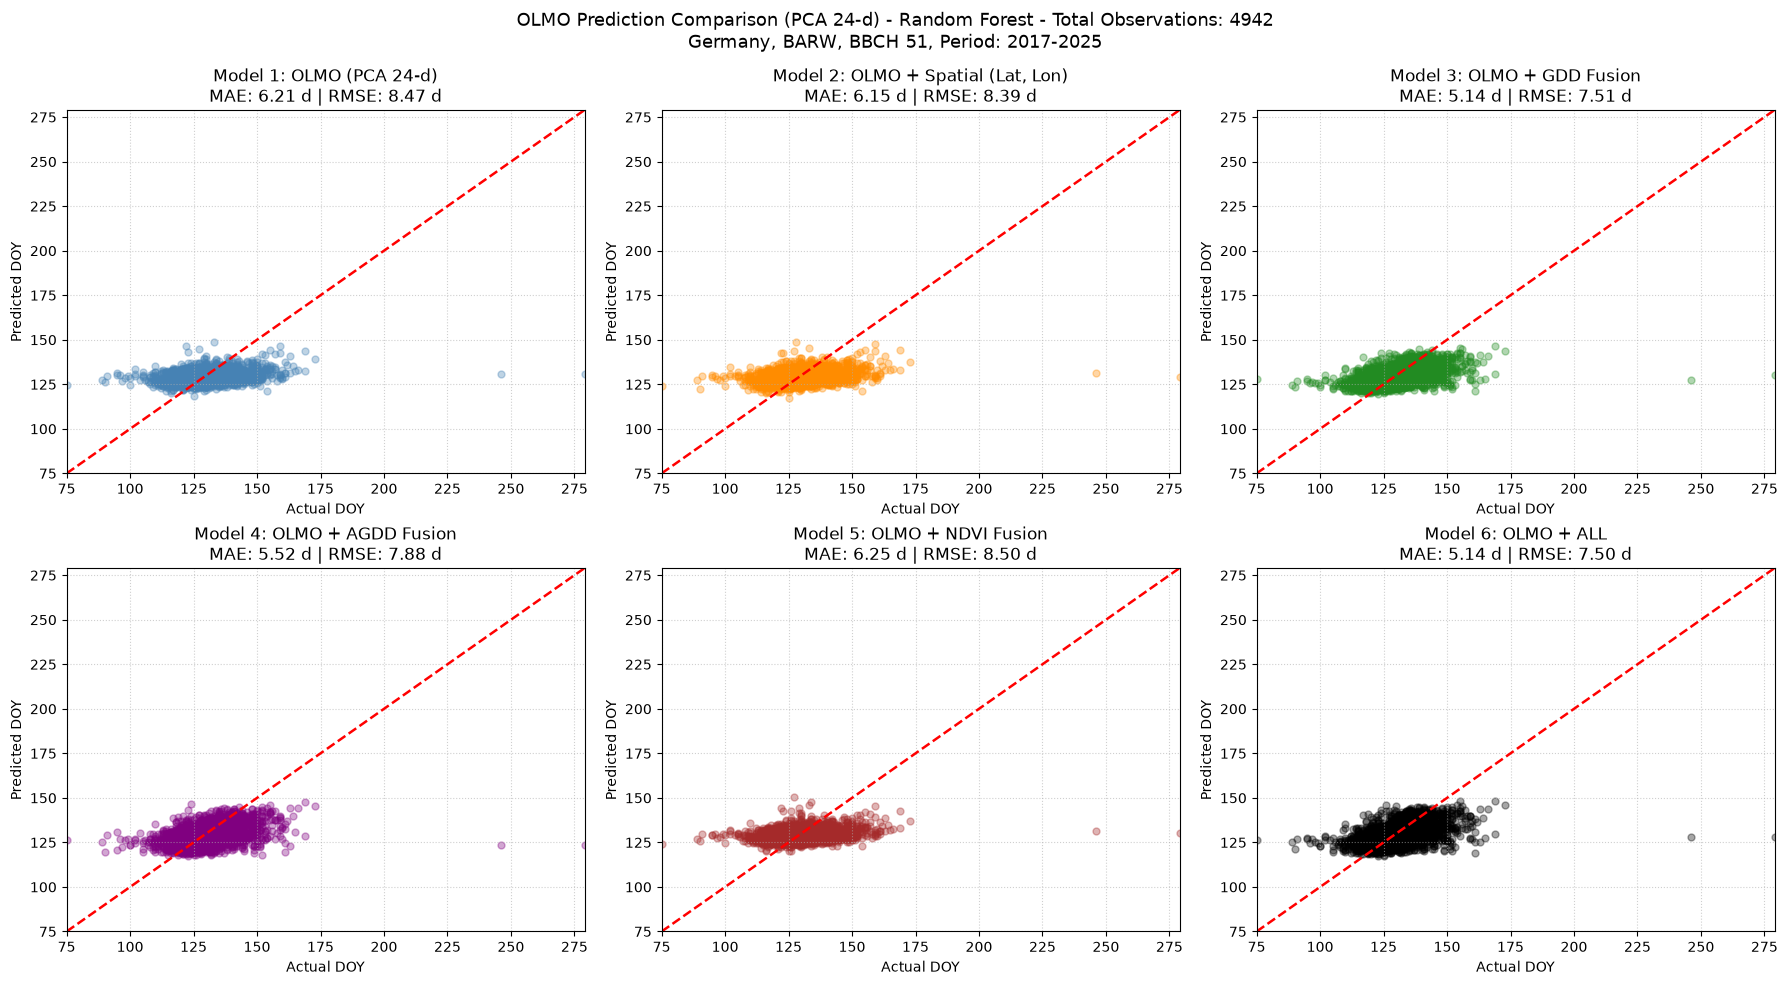

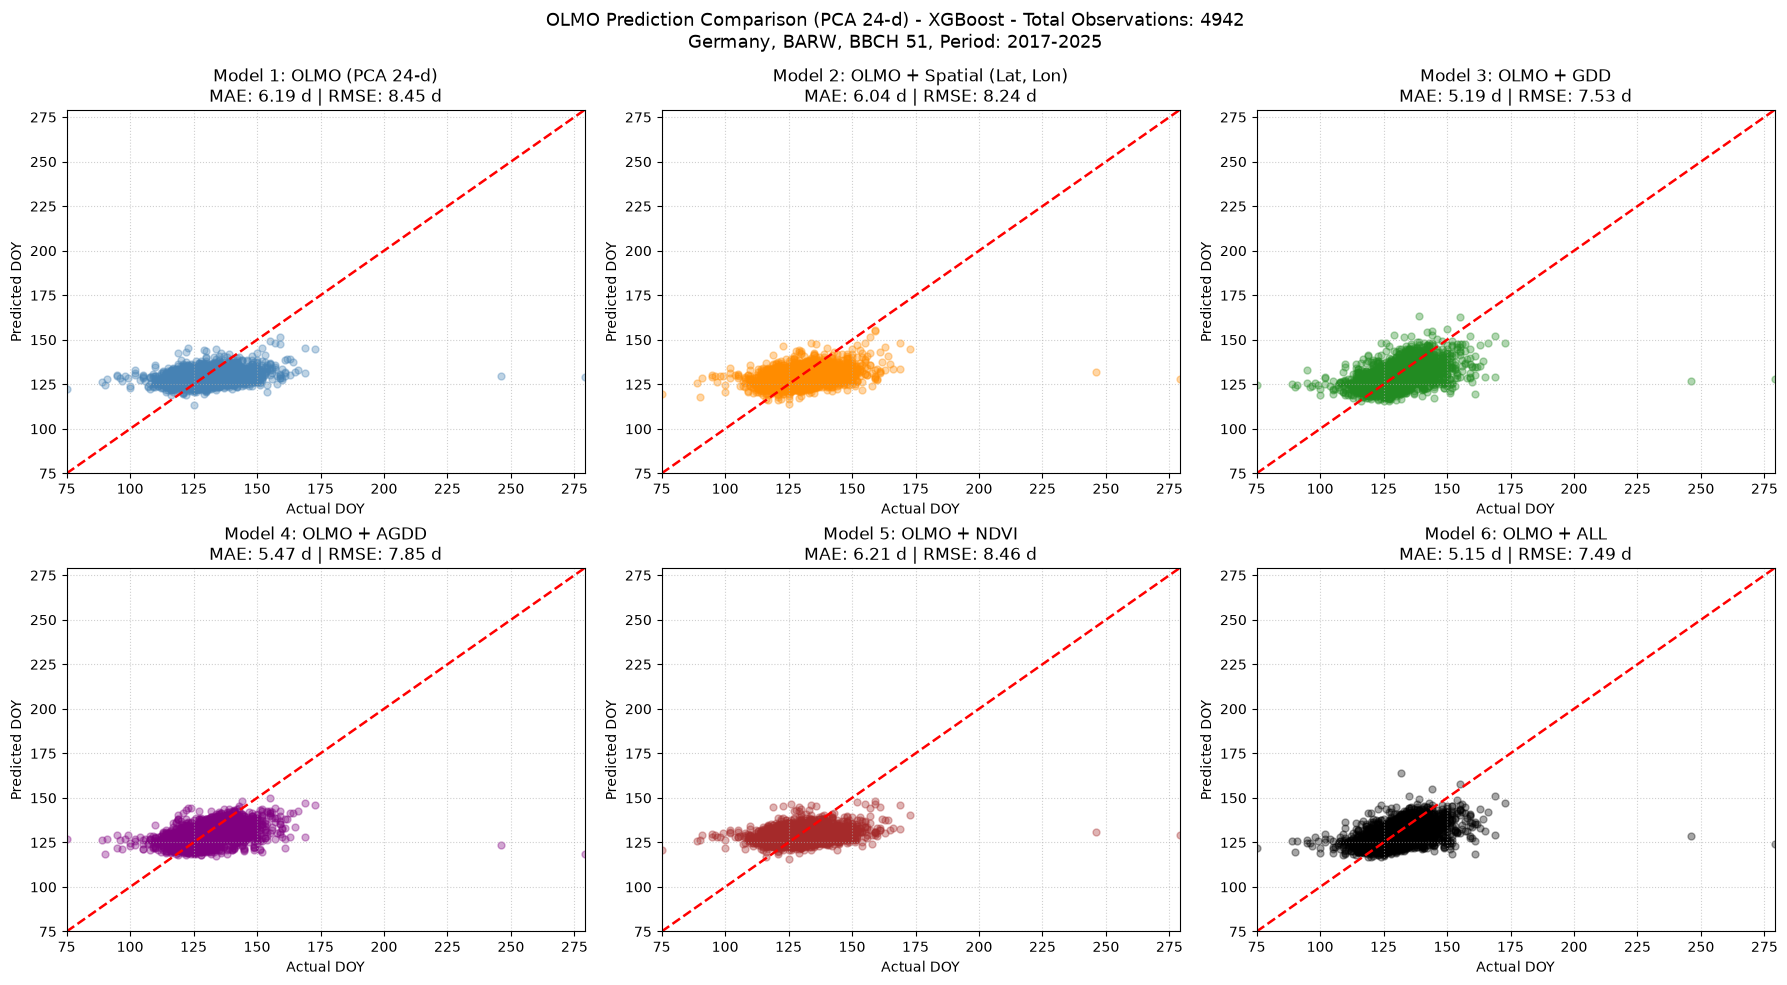

In [85]:
results_dir = Path("Results")
summary_save_path = (
    results_dir / f"{selected_folder.name}" / f"LOYOCV_{model}_PCA"
)
summary_save_path.mkdir(parents=True, exist_ok=True)

df_folds_rf = pd.DataFrame(fold_results_rf)
df_folds_xgb = pd.DataFrame(fold_results_xgb)

print("=" * 85)
print(f"OVERALL LOYOCV BENCHMARK: {model} REDUCED (PCA {N_PCA_COMPONENTS}-d)")
print("=" * 85)

for model_key in baselines.keys():
  mae_rf = mean_absolute_error(actual_doy, rf_preds[model_key])
  rmse_rf = np.sqrt(mean_squared_error(actual_doy, rf_preds[model_key]))
  mae_xgb = mean_absolute_error(actual_doy, xgb_preds[model_key])
  rmse_xgb = np.sqrt(mean_squared_error(actual_doy, xgb_preds[model_key]))

  print(
      f"Model {model_key} | RF MAE: {mae_rf:5.2f}d, RMSE: {rmse_rf:5.2f}d |"
      f" XGB MAE: {mae_xgb:5.2f}d, RMSE: {rmse_xgb:5.2f}d"
  )

# Export fold-level summaries
df_folds_rf.to_csv(summary_save_path / f"{model.lower()}summary_rf_pca.csv", sep=";", index=False)
df_folds_xgb.to_csv(
    summary_save_path / f"{model.lower()}_summary_xgboost_pca.csv", sep=";", index=False
)

print(f"\nSummaries successfully saved to: {summary_save_path.resolve()}")

# Plots
# 1. Scatter Plots for Random Forest (PCA-Reduced)
plt.figure(figsize=(18, 10))

models_plot_rf = [
    (
        f"Model 1: {model} (PCA {N_PCA_COMPONENTS}-d)",
        rf_preds["M1"],
        mean_absolute_error(actual_doy, rf_preds["M1"]),
        np.sqrt(mean_squared_error(actual_doy, rf_preds["M1"])),
        "steelblue",
    ),
    (
        f"Model 2: {model} + Spatial (Lat, Lon)",
        rf_preds["M2"],
        mean_absolute_error(actual_doy, rf_preds["M2"]),
        np.sqrt(mean_squared_error(actual_doy, rf_preds["M2"])),
        "darkorange",
    ),
    (
        f"Model 3: {model} + GDD Fusion",
        rf_preds["M3"],
        mean_absolute_error(actual_doy, rf_preds["M3"]),
        np.sqrt(mean_squared_error(actual_doy, rf_preds["M3"])),
        "forestgreen",
    ),
    (
        f"Model 4: {model} + AGDD Fusion",
        rf_preds["M4"],
        mean_absolute_error(actual_doy, rf_preds["M4"]),
        np.sqrt(mean_squared_error(actual_doy, rf_preds["M4"])),
        "purple",
    ),
    (
        f"Model 5: {model} + NDVI Fusion",
        rf_preds["M5"],
        mean_absolute_error(actual_doy, rf_preds["M5"]),
        np.sqrt(mean_squared_error(actual_doy, rf_preds["M5"])),
        "brown",
    ),
    (
        f"Model 6: {model} + ALL",
        rf_preds["M6"],
        mean_absolute_error(actual_doy, rf_preds["M6"]),
        np.sqrt(mean_squared_error(actual_doy, rf_preds["M6"])),
        "black",
    ),
]

min_val = min(actual_doy)
max_val = max(actual_doy)

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot_rf, 1):
  plt.subplot(2, 3, i)
  plt.scatter(actual_doy, predictions, alpha=0.35, color=color, s=25)
  plt.plot(
      [min_val, max_val], [min_val, max_val], "r--", lw=1.8, label="1:1 Fit"
  )
  plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d")
  plt.xlabel("Actual DOY")
  plt.ylabel("Predicted DOY")
  plt.grid(True, linestyle=":", alpha=0.6)
  plt.xlim(min_val, max_val)
  plt.ylim(min_val, max_val)

plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.suptitle(
    f"{model} Prediction Comparison (PCA {N_PCA_COMPONENTS}-d) - Random Forest"
    f" - Total Observations: {len(df_clean)}\n{final_name}",
    fontsize=13,
)

# Save Random Forest figure
rf_plot_path = (
    summary_save_path / f"scatter_comparison_{model.lower()}_rf_pca_reduced.png"
)
plt.savefig(rf_plot_path, dpi=300, bbox_inches="tight")
plt.show()


# Scatter Plots for XGBoost (PCA-Reduced)
plt.figure(figsize=(18, 10))

models_plot_xgb = [
    (
        f"Model 1: {model} (PCA {N_PCA_COMPONENTS}-d)",
        xgb_preds["M1"],
        mean_absolute_error(actual_doy, xgb_preds["M1"]),
        np.sqrt(mean_squared_error(actual_doy, xgb_preds["M1"])),
        "steelblue",
    ),
    (
        f"Model 2: {model} + Spatial (Lat, Lon)",
        xgb_preds["M2"],
        mean_absolute_error(actual_doy, xgb_preds["M2"]),
        np.sqrt(mean_squared_error(actual_doy, xgb_preds["M2"])),
        "darkorange",
    ),
    (
        f"Model 3: {model} + GDD",
        xgb_preds["M3"],
        mean_absolute_error(actual_doy, xgb_preds["M3"]),
        np.sqrt(mean_squared_error(actual_doy, xgb_preds["M3"])),
        "forestgreen",
    ),
    (
        f"Model 4: {model} + AGDD",
        xgb_preds["M4"],
        mean_absolute_error(actual_doy, xgb_preds["M4"]),
        np.sqrt(mean_squared_error(actual_doy, xgb_preds["M4"])),
        "purple",
    ),
    (
        f"Model 5: {model} + NDVI",
        xgb_preds["M5"],
        mean_absolute_error(actual_doy, xgb_preds["M5"]),
        np.sqrt(mean_squared_error(actual_doy, xgb_preds["M5"])),
        "brown",
    ),
    (
        f"Model 6: {model} + ALL",
        xgb_preds["M6"],
        mean_absolute_error(actual_doy, xgb_preds["M6"]),
        np.sqrt(mean_squared_error(actual_doy, xgb_preds["M6"])),
        "black",
    ),
]

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot_xgb, 1):
  plt.subplot(2, 3, i)
  plt.scatter(actual_doy, predictions, alpha=0.35, color=color, s=25)
  plt.plot(
      [min_val, max_val], [min_val, max_val], "r--", lw=1.8, label="1:1 Fit"
  )
  plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d")
  plt.xlabel("Actual DOY")
  plt.ylabel("Predicted DOY")
  plt.grid(True, linestyle=":", alpha=0.6)
  plt.xlim(min_val, max_val)
  plt.ylim(min_val, max_val)

plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.suptitle(
    f"{model} Prediction Comparison (PCA {N_PCA_COMPONENTS}-d) - XGBoost -"
    f" Total Observations: {len(df_clean)}\n{final_name}",
    fontsize=13,
)

# Save XGBoost figure
xgb_plot_path = (
    summary_save_path / f"scatter_comparison_{model.lower()}_xgboost_pca_reduced.png"
)
plt.savefig(xgb_plot_path, dpi=300, bbox_inches="tight")
plt.show()


### 4.5 $R^2$ Decomposition & Per-Year LOYOCV Trajectory Plots (PCA-Reduced Embeddings, RF & XGBoost)

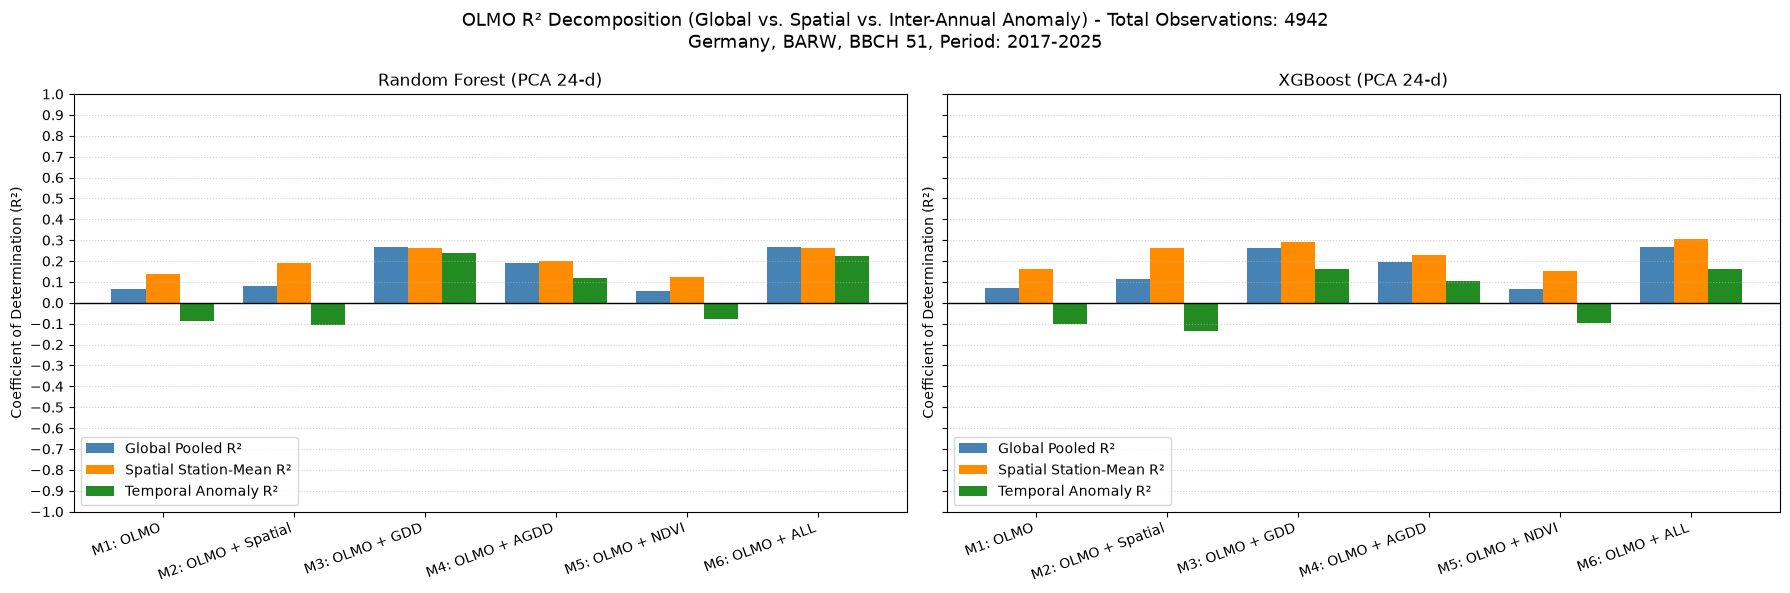

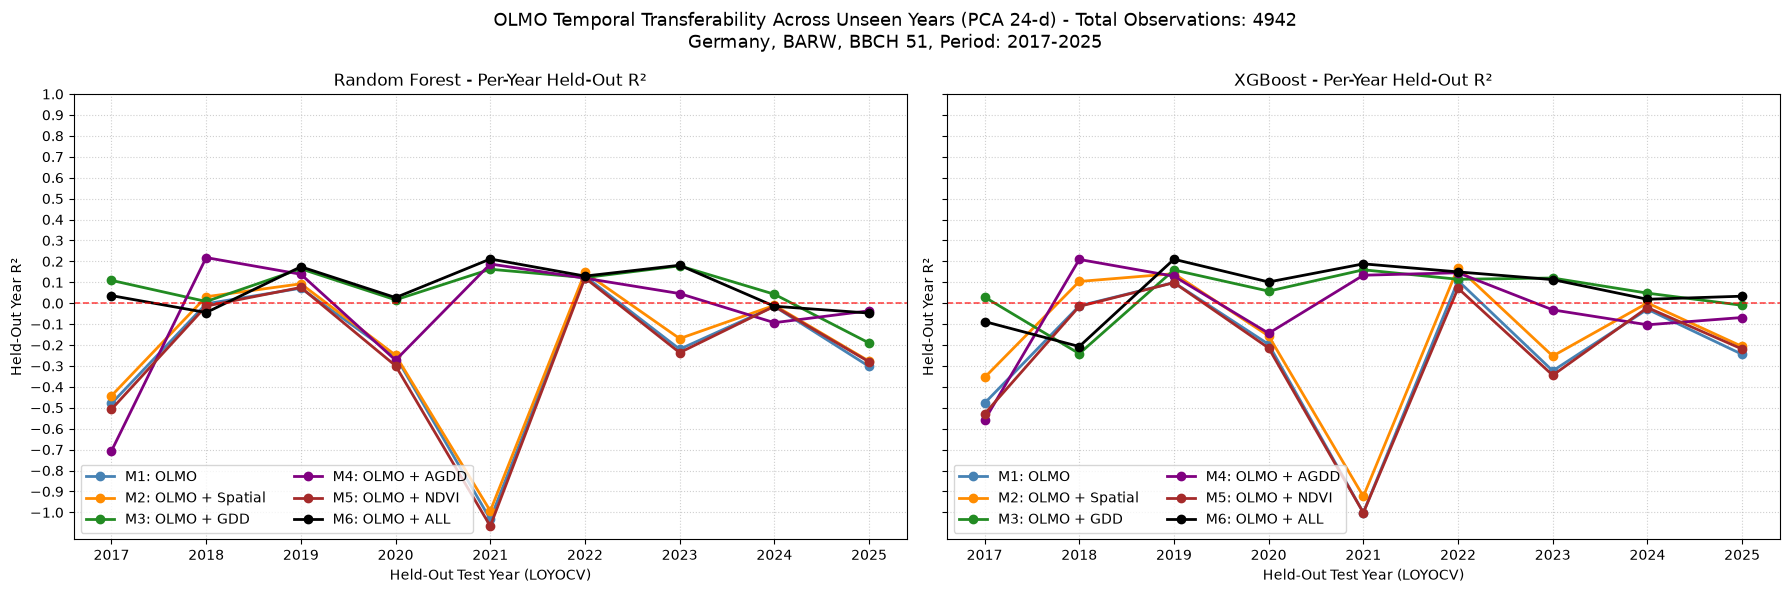

In [89]:
from sklearn.metrics import r2_score

# Ensure actual_doy is a NumPy array so boolean masking works cleanly
actual_doy_arr = np.asarray(actual_doy)

# R² Decomposition Plot: Global vs. Spatial vs. Temporal Anomaly R²
if "PEP_ID" in df_clean.columns:
  station_ids = df_clean["PEP_ID"].values
else:
  station_ids = (
      df_clean["Latitude"].round(4).astype(str)
      + "_"
      + df_clean["Longitude"].round(4).astype(str)
  ).values

years_arr = df_clean["Year"].astype(int).values
model_keys = ["M1", "M2", "M3", "M4", "M5", "M6"]
model_short_labels = [
    f"M1: {model}",
    f"M2: {model} + Spatial",
    f"M3: {model} + GDD",
    f"M4: {model} + AGDD",
    f"M5: {model} + NDVI",
    f"M6: {model} + ALL",
]

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
pca_decomp_dfs = {}

for ax, algo_name, preds_dict in [
    (axes[0], "Random Forest", rf_preds),
    (axes[1], "XGBoost", xgb_preds),
]:
  global_r2_list = []
  spatial_r2_list = []
  temporal_r2_list = []

  for m_key in model_keys:
    preds = np.asarray(preds_dict[m_key])

    # 1. Global Pooled R²
    g_r2 = r2_score(actual_doy_arr, preds)

    # 2. Spatial Station-Mean R² & 3. Temporal Anomaly R² (ΔDOY)
    df_tmp = pd.DataFrame({
        "Station": station_ids,
        "Actual": actual_doy_arr,
        "Pred": preds,
    })
    st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
    s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

    df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
    obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
    pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
    t_r2 = r2_score(obs_anom, pred_anom)

    global_r2_list.append(g_r2)
    spatial_r2_list.append(s_r2)
    temporal_r2_list.append(t_r2)

  pca_decomp_dfs[algo_name] = pd.DataFrame({
      "Model_Key": model_keys,
      "Model_Label": model_short_labels,
      "Global_Pooled_R2": np.round(global_r2_list, 4),
      "Spatial_Station_Mean_R2": np.round(spatial_r2_list, 4),
      "Temporal_Anomaly_R2": np.round(temporal_r2_list, 4),
  })

  x_pos = np.arange(len(model_keys))
  bar_width = 0.26

  ax.bar(
      x_pos - bar_width,
      global_r2_list,
      width=bar_width,
      label="Global Pooled R²",
      color="steelblue",
  )
  ax.bar(
      x_pos,
      spatial_r2_list,
      width=bar_width,
      label="Spatial Station-Mean R²",
      color="darkorange",
  )
  ax.bar(
      x_pos + bar_width,
      temporal_r2_list,
      width=bar_width,
      label="Temporal Anomaly R²",
      color="forestgreen",
  )

  ax.axhline(0, color="black", lw=1.0)
  ax.set_xticks(x_pos)
  ax.set_xticklabels(model_short_labels, rotation=20, ha="right")
  ax.set_yticks(y_ticks)
  ax.set_title(f"{algo_name} (PCA {N_PCA_COMPONENTS}-d)")
  ax.set_ylabel("Coefficient of Determination (R²)")
  ax.grid(True, axis="y", linestyle=":", alpha=0.6)
  ax.legend(loc="lower left", frameon=True)

# Save R² Decomposition values to CSVs (RF & XGBoost)
df_r2_decomposition_rf_pca = pca_decomp_dfs["Random Forest"]
df_r2_decomposition_xgb_pca = pca_decomp_dfs["XGBoost"]
display(df_r2_decomposition_rf_pca)
display(df_r2_decomposition_xgb_pca)
df_r2_decomposition_rf_pca.to_csv(
    summary_save_path / f"r2_decomposition_{model.lower()}_rf_pca_reduced.csv",
    sep=";",
    index=False,
)
df_r2_decomposition_xgb_pca.to_csv(
    summary_save_path / f"r2_decomposition_{model.lower()}_xgboost_pca_reduced.csv",
    sep=";",
    index=False,
)

plt.tight_layout()
plt.subplots_adjust(top=0.84)
plt.suptitle(
    f"{model} R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) -"
    f" Total Observations: {len(df_clean)}\n{final_name}",
    fontsize=13,
)

r2_decomp_path = (
    summary_save_path / f"r2_decomposition_{model.lower()}_pca_reduced.png"
)
plt.savefig(r2_decomp_path, dpi=300, bbox_inches="tight")
plt.show()

# Per-Year LOYOCV R² Trajectory Across Held-Out Years (M1 to M6)
unique_years = sorted(np.unique(years_arr))
line_colors = [
    "steelblue",
    "darkorange",
    "forestgreen",
    "purple",
    "brown",
    "black",
]

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
pca_yearly_dfs = {}

for ax, algo_name, preds_dict in [
    (axes[0], "Random Forest", rf_preds),
    (axes[1], "XGBoost", xgb_preds),
]:
  df_yr = pd.DataFrame({"Test_Year": unique_years})
  for m_key, m_label, color in zip(model_keys, model_short_labels, line_colors):
    preds = np.asarray(preds_dict[m_key])
    yearly_r2 = []
    for yr in unique_years:
      mask = years_arr == yr
      yearly_r2.append(r2_score(actual_doy_arr[mask], preds[mask]))

    df_yr[f"{m_key}_R2"] = np.round(yearly_r2, 4)

    ax.plot(
        unique_years,
        yearly_r2,
        marker="o",
        lw=2,
        color=color,
        label=m_label,
    )

  pca_yearly_dfs[algo_name] = df_yr
  ax.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
  ax.set_title(f"{algo_name} - Per-Year Held-Out R²")
  ax.set_xlabel("Held-Out Test Year (LOYOCV)")
  ax.set_ylabel("Held-Out Year R²")
  ax.set_xticks(unique_years)
  ax.set_yticks(y_ticks)
  ax.grid(True, linestyle=":", alpha=0.6)
  ax.legend(loc="lower left", ncol=2, frameon=True)

# Save Per-Year R² values to CSVs (RF & XGBoost)
df_r2_per_year_rf_pca = pca_yearly_dfs["Random Forest"]
df_r2_per_year_xgb_pca = pca_yearly_dfs["XGBoost"]
display(df_r2_per_year_rf_pca)
display(df_r2_per_year_xgb_pca)
df_r2_per_year_rf_pca.to_csv(
    summary_save_path / f"r2_per_year_{model.lower()}_rf_pca_reduced.csv",
    sep=";",
    index=False,
)
df_r2_per_year_xgb_pca.to_csv(
    summary_save_path / f"r2_per_year_{model.lower()}_xgboost_pca_reduced.csv",
    sep=";",
    index=False,
)

plt.tight_layout()
plt.subplots_adjust(top=0.84)
plt.suptitle(
    f"{model} Temporal Transferability Across Unseen Years (PCA"
    f" {N_PCA_COMPONENTS}-d) - Total Observations: {len(df_clean)}\n{final_name}",
    fontsize=13,
)

r2_yearly_path = (
    summary_save_path / f"r2_per_year_{model.lower()}_pca_reduced.png"
)
plt.savefig(r2_yearly_path, dpi=300, bbox_inches="tight")
plt.show()